# Grover's Algorithm: A Complete, Hands-On Guide

This notebook teaches Grover's algorithm from first principles to practical applications. It merges and extends five earlier notebooks:

| Source notebook | What it contributed |
|---|---|
| `022-GroverAlgorithm-01` | Theory (oracle, amplitude amplification, geometry) and the 3-qubit circuits |
| `022-GroverAlgorithm-02` | Building oracles from Boolean logic (reversible AND / OR), 3-SAT by hand, iteration sweep |
| `022-GroverAlgorithm-03` | Classical baseline, the 2-qubit "Queen of Hearts" demo, 3-SAT with `PhaseOracle` + `Grover` |
| `321-Grover Optimization` | Grover Adaptive Search (GAS) on QUBO problems |
| `504-Grover Optimization` | GAS edge cases (zero objective, maximisation) and result validation |

### Learning goals
By the end you should be able to:
1. Explain **why** Grover's algorithm gives a quadratic speed-up, using both the *amplitude bar picture* and the *2-D rotation picture*.
2. Build the two core components, the **oracle** and the **diffuser**, gate by gate, for any number of qubits.
3. Compute the **optimal number of iterations** and explain what happens if you do too few or too many.
4. Turn a **Boolean formula (3-SAT)** into an oracle, both by hand and with Qiskit's `PhaseOracle`.
5. Use **Grover Adaptive Search** to solve small binary optimisation (QUBO) problems.
6. Understand what happens to Grover circuits on **noisy real hardware**.

### Prerequisites
Qubits, superposition, the Hadamard ($H$), Pauli ($X$, $Z$) and controlled gates ($CX$, $CZ$, Toffoli), and reading a measurement histogram.

### Contents
1. The search problem: classical vs quantum
2. Theory: oracle, diffuser, amplitude amplification, geometry
3. Setup
4. The smallest example: find 1 card out of 4 (2 qubits)
5. Watching the amplitudes move (statevector view)
6. Three qubits, two marked states
7. General $n$-qubit Grover and the optimal number of iterations
8. Building an oracle from Boolean logic: 3-SAT by hand
9. The library way: `PhaseOracle` + `Grover` on a 32-card 3-SAT
10. Beyond search: Grover Adaptive Search for optimisation
11. Running on (noisy) hardware
12. Summary, exercises and references

## 1. The search problem: classical vs quantum

Grover's algorithm speeds up **unstructured search** quadratically. It can also be used as a general trick, called **amplitude amplification**, or as a subroutine that gives a quadratic speed-up to many other algorithms.

### Unstructured search
Suppose we have a large list of $N$ items. Exactly one item $w$ has a property we are looking for. For example, we want to find a single blue ball among $N-1$ grey balls.

<img src="images/grover_search.png">

The list has **no structure** we can use: it is not sorted, and there is no index to look things up in. So a classical computer must check the items one at a time:
- on average about $N/2$ checks,
- in the worst case $N$ (strictly $N-1$, because once only one item is left we know it is the answer).

Grover's algorithm needs only about $\frac{\pi}{4}\sqrt{N}$ queries.

| $N$ | Classical (average) | Grover ($\approx \frac{\pi}{4}\sqrt N$) |
|---|---|---|
| 4 | 2.25 | **1** |
| 32 | ~16.5 | **4** |
| 1,000,000 | ~500,000 | **~785** |

### Formal definition
We are given an **oracle function** $f:\{0,1\}^n \to \{0,1\}$ with $f(x)=1$ only for the item(s) we want. The goal is to find $w$ such that $f(w)=1$.

Another way to say this: Grover's algorithm **inverts a function**. If we can evaluate $y=f(x)$ on a quantum computer, Grover finds an $x$ that produces a given $y$. "Searching a database" is a special case: we build an $f$ that returns 1 exactly when $x$ is the entry we are looking for.

### Worked example: 1 card out of 4
We hide the Queen of Hearts among four face-down queens and turn cards over at random until we find it:

| Draw | Probability the game ends here | Draws used | p × q |
|---|---|---|---|
| First | 1/4 | 1 | 0.25 |
| Second | 1/4 | 2 | 0.50 |
| Third (1) | 1/2 | 3 | 1.50 |
| **Average** | | | **2.25** |

(1) After the third draw we know where the queen is, whether or not we turned it over, so no fourth draw is needed.

Grover's algorithm finds it in a **single** query, with certainty.

### Code: measuring the classical cost by simulation

**What this cell does.** It runs the classical "turn cards over at random" strategy many times and reports the average number of draws needed. This gives us the classical baseline that Grover's algorithm will beat.

**How it works, step by step:**
1. `hide(n)` builds a list of `n` cards, all `0` except one `1` (the hidden queen) at a random position.
2. `find(cards)` plays the game:
   - while more than one card is left, it picks a random card and counts one draw;
   - if that card is the `1`, it stops;
   - otherwise it **removes** that card (we never turn the same card over twice) and continues;
   - if only one card is left, no draw is needed because we know where the queen is.
3. The main loop repeats the game `draws = 1000` times with `length = 32` cards and prints the average.

**What to expect.** For 32 cards, about 16.5 draws, i.e. roughly $N/2$. Change `length` to 4 to reproduce the 2.25 from the table above. Grover's algorithm needs only 4 queries for $N=32$ (see section 9).

In [1]:
# Classical way: hide one card at a random position, then count the attempts needed to find it.
from random import randint

def hide(n):
    """Create a list of n zeros with a single 1 at a random position."""
    cards = [0 for i in range(n)]  # only 0s
    position = randint(0, n - 1)   # draw a random position
    cards[position] = 1            # this position now holds the 1 (others keep 0)
    return cards

def find(cards):
    """Turn cards over at random (without replacement) until the 1 is found; return the number of draws."""
    n = 0  # attempts needed to find the hidden position
    while len(cards) > 1:  # when one card is left, we know it is the hidden one
        trial = randint(0, len(cards) - 1)  # try one position at random
        n += 1
        if cards[trial]:
            break
        # remove that card from the list
        cards = cards[0:trial] + cards[trial + 1:len(cards)]
    return n

# length = number of face-down cards (try 4, 32, 1000 ...)
# draws  = number of times the game is played, to compute an average
length = 32
draws = 1000

total = 0
for d in range(draws):
    total += find(hide(length))

print(f"With {length} cards and {draws} experiments:")
print(f"    the hidden card was found in an average of {total/draws:.2f} draws")

With 32 cards and 1000 experiments:
    the hidden card was found in an average of 16.45 draws


## 2. Theory

Grover's algorithm repeats one step over and over. Each step has two parts:

$$\text{Grover iteration } G = \underbrace{U_s}_{\text{diffuser}}\;\underbrace{U_f}_{\text{oracle}}$$

### 2.1 Encoding the items
We label each item with an $n$-bit string $x \in \{0,1\}^n$, so $N = 2^n$ items fit in $n$ qubits. For example, 3 qubits can hold 8 items, $|000\rangle \dots |111\rangle$.

### 2.2 The oracle $U_f$: marking the answer with a minus sign
The oracle is a unitary that **flips the sign** (phase) of the marked item and leaves everything else unchanged:

$$U_f\,|x\rangle = (-1)^{f(x)}\,|x\rangle =
\begin{cases} -|x\rangle & \text{if } x = w \\ \phantom{-}|x\rangle & \text{otherwise}\end{cases}$$

So the oracle does nothing to an unwanted item and maps $|w\rangle \to -|w\rangle$. Geometrically, it is a reflection in the $N$-dimensional state space.

A minus sign alone cannot be measured: $|-a|^2 = |a|^2$. The diffuser's job is to turn that sign into a larger amplitude.

> **Phase oracle vs bit-flip oracle.** A classical-style circuit usually computes $f(x)$ into an extra "output" qubit: $|x\rangle|y\rangle \to |x\rangle|y\oplus f(x)\rangle$. If the output qubit starts in $|-\rangle = (|0\rangle-|1\rangle)/\sqrt2$, this becomes $|x\rangle|-\rangle \to (-1)^{f(x)}|x\rangle|-\rangle$. The sign "kicks back" onto the input. This is called **phase kickback**, and section 8 uses it.

### 2.3 The starting point: uniform superposition
We know nothing about where $w$ is, so we start with every item equally likely:

$$|s\rangle = H^{\otimes n}|0\rangle^{\otimes n} = \frac{1}{\sqrt N}\sum_{x=0}^{N-1}|x\rangle$$

Measuring $|s\rangle$ right away would give $w$ with probability only $1/N$.

### 2.4 The diffuser $U_s$: inversion about the mean
$$U_s = 2|s\rangle\langle s| - I$$

This operator reflects the state about $|s\rangle$. In terms of amplitudes, it maps every amplitude $a_x \to 2\bar a - a_x$, where $\bar a$ is the **mean** amplitude. This is why it is called **inversion about the mean**.

How it is built from gates:

$$U_s = H^{\otimes n}\,(2|0\rangle\langle 0| - I)\,H^{\otimes n}$$

and $(2|0\rangle\langle0| - I)$, which flips the sign of every state **except** $|0\dots0\rangle$, is implemented (up to an irrelevant global phase of $-1$) as

$$X^{\otimes n}\;\cdot\; \text{(multi-controlled } Z) \;\cdot\; X^{\otimes n}$$

The multi-controlled $Z$ is built as $H$ on the target, a multi-controlled $X$ (Toffoli for 3 qubits), then $H$ on the target again.

So the full diffuser is: **H on all → X on all → MCZ → X on all → H on all**.

### 2.5 Amplitude amplification, step by step

**Step 0.** Start in $|s\rangle$. All amplitudes are equal. The dashed line marks the mean amplitude.

<img src="images/grover_step0.png">

The 2-D plane is spanned by $|w\rangle$ and $|s'\rangle$. Here $|s'\rangle$ is $|s\rangle$ with the $|w\rangle$ component removed and the rest rescaled, so it is orthogonal to $|w\rangle$.

**Step 1: oracle.** $U_f$ flips the sign of the $|w\rangle$ amplitude. This also **lowers the mean** slightly. In the plane, the state is reflected about $|s'\rangle$.

<img src="images/grover_step1.png">

**Step 2: diffuser.** $U_s$ reflects every amplitude about the (now lower) mean. The negative amplitude of $|w\rangle$ ends up far **above** the mean: roughly three times its original size on the first step. All the other amplitudes shrink a little.

<img src="images/grover_step2.png">

Two reflections make a **rotation**. Each Grover iteration rotates the state a little closer to $|w\rangle$. After $t$ iterations the state is $|\psi_t\rangle = (U_s U_f)^t|s\rangle$.

<img src="images/grover_algorithm.png">

### 2.6 How many iterations? (the most important formula in this notebook)

Let $M$ be the number of marked items among $N$. Define an angle $\theta$ by

$$\sin\theta = \sqrt{\frac{M}{N}}$$

The starting state $|s\rangle$ makes angle $\theta$ with the "bad" direction $|s'\rangle$. **Each Grover iteration rotates the state by $2\theta$** towards $|w\rangle$. After $k$ iterations:

$$P_{\text{success}}(k) = \sin^2\!\big((2k+1)\,\theta\big)$$

We want $(2k+1)\theta \approx \pi/2$, which gives

$$k_{\text{opt}} = \left\lfloor \frac{\pi}{4\theta} \right\rfloor \approx \frac{\pi}{4}\sqrt{\frac{N}{M}}$$

Key consequences:
- The cost grows like $\sqrt N$, not $N$. **That is the quadratic speed-up.**
- **More iterations are not better.** Past $k_{\text{opt}}$ the state rotates *past* $|w\rangle$ and the success probability falls again (it oscillates). Section 7 shows this, and so does the 3-SAT experiment in section 8.
- More solutions ($M$ larger) means fewer iterations are needed.
- Special cases to remember: $N=4, M=1 \Rightarrow \theta = 30°$, so **one** iteration gives exactly 100%. $N=8, M=2$ is the same angle, so also one iteration and 100%.

## 3. Setup

### Code: backend setup (shared by all notebooks in this repo)

**What this cell does.** It loads the repo's helper module `qiskit_backend_config.py`, which makes older-style code run on Qiskit 2.x, and creates a `backend` object that the rest of the notebook runs circuits on.

**Details:**
- `sys.path.insert(...)` lets Python find `qiskit_backend_config.py` in the same folder as this notebook.
- `get_backend(...)` returns a local **Aer simulator** for names like `"qasm_simulator"`, or a real IBM device when given a device name and an API token.
- `execute(circuit, backend, shots=...)` replaces the old `qiskit.execute()`: it transpiles the circuit for the backend, runs it, and returns a result whose `.get_counts()` gives the measurement histogram.
- The IBM token is read from the environment variable `IBM_QUANTUM_TOKEN`. **Never paste a token directly into a notebook.** Notebooks get committed and shared, and then the token leaks.

Leave `BACKEND_NAME = "qasm_simulator"` for everything except section 11.

In [2]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')

Backend ready: LegacyAerSimulator('aer_simulator')


### Code: imports

**What this cell does.** It imports everything the notebook uses, in one place, so later cells stay focused on the algorithm.

| Import | Used for |
|---|---|
| `numpy`, `matplotlib` | maths and plots (amplitude bar charts, success-probability curves) |
| `QuantumCircuit`, `QuantumRegister`, `ClassicalRegister` | building circuits |
| `Statevector` | exact, noise-free state of a circuit (no sampling), to "look inside" the algorithm |
| `plot_histogram` | measurement histograms |
| `PhaseOracle` | builds an oracle circuit directly from a Boolean formula (section 9) |
| `StatevectorSampler` | exact local sampler used by `qiskit_algorithms` and `qiskit_optimization` |
| `Grover`, `AmplificationProblem` | Qiskit's ready-made Grover implementation (section 9) |
| `GroverOptimizer`, `MinimumEigenOptimizer`, `NumPyMinimumEigensolver`, `from_docplex_mp`, `Model` | Grover Adaptive Search and an exact classical solver to check it against (section 10) |

`%matplotlib inline` makes figures appear directly under the cells that create them.

In [3]:
%matplotlib inline
import itertools
import os
import random
import tempfile
from math import asin, floor, pi, sqrt

import matplotlib.pyplot as plt
import numpy as np

from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit.circuit.library import PhaseOracle
from qiskit.primitives import StatevectorSampler

from qiskit_algorithms import Grover, AmplificationProblem

from qiskit_optimization.algorithms import GroverOptimizer, MinimumEigenOptimizer
from qiskit_optimization.minimum_eigensolvers import NumPyMinimumEigensolver
from qiskit_optimization.translators import from_docplex_mp
from docplex.mp.model import Model

print("Imports OK")

Imports OK


> **Bit ordering in Qiskit (read this once, it saves hours of confusion).**
> Qiskit is *little-endian*: qubit 0 is the **right-most** character of a bitstring. So the string `'110'` means $q_2=1,\ q_1=1,\ q_0=0$. When a formula's variables $a, b, c$ sit on qubits $0, 1, 2$, the bitstring you read from a histogram is **c b a**. You have to reverse it to read $a, b, c$ in order. This notebook points this out every time it matters.

## 4. The smallest example: find 1 card out of 4 (2 qubits)

Four positions need $n=2$ qubits: `00`, `01`, `10`, `11`. With $N=4$ and $M=1$, section 2.6 says **one** Grover iteration gives the answer with 100% probability.

The circuit is:

```
|0>─H─┤        ├─┤          ├─M
      │ Oracle │ │ Diffuser │
|0>─H─┤        ├─┤          ├─M
```

### Code: the 2-qubit oracle and diffuser

**What this cell does.** It defines two functions that each return a small reusable circuit (a "gate").

**`two_qubit_oracle(secret)`** flips the sign of exactly one basis state, `|secret>`:
- A `CZ` gate flips the sign of `|11>` only (it applies $-1$ when both qubits are 1).
- To mark a different state, such as `|01>`, we first apply `X` to every qubit whose bit in `secret` is `0`. That turns the target state into `|11>`. Then we apply `CZ`, then undo the `X` gates. This "X–CZ–X sandwich" is the standard way to mark any bitstring.
- `reversed(secret)` is used because of Qiskit's bit ordering: character 0 of the string belongs to the **highest** qubit.

**`two_qubit_diffuser()`** implements $U_s = 2|s\rangle\langle s| - I$ using the recipe from section 2.4: `H` on all, then `X` on all, then `CZ`, then `X` on all, then `H` on all.

> In the original `022-GroverAlgorithm-03` notebook, the `CZ` was written as `H–CX–H` on the target, and the "hide" gates used pairs of `S` gates ($S\cdot S = Z$). Those are equivalent constructions; the X–CZ–X form here is easier to read.

The last lines draw both circuits so you can match each gate to the description above.

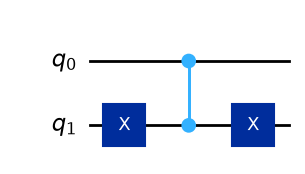

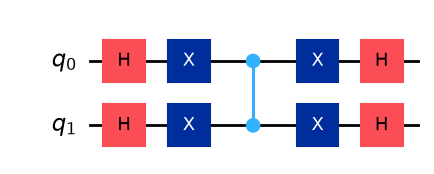

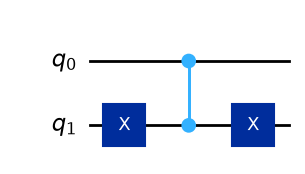

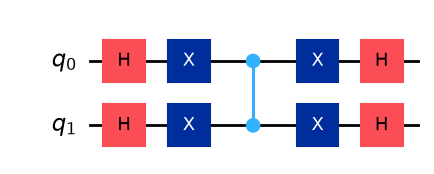

In [4]:
def two_qubit_oracle(secret):
    """Phase oracle on 2 qubits: |secret> -> -|secret>, all other basis states unchanged.

    `secret` is a 2-character bitstring in Qiskit order (q1 q0), e.g. '01'.
    """
    qc = QuantumCircuit(2, name=f"Oracle")
    zeros = [q for q, bit in enumerate(reversed(secret)) if bit == '0']
    if zeros:
        qc.x(zeros)        # map |secret> -> |11>
    qc.cz(0, 1)            # flip the sign of |11>
    if zeros:
        qc.x(zeros)        # map back
    return qc

def two_qubit_diffuser():
    """Inversion about the mean on 2 qubits: H X CZ X H."""
    qc = QuantumCircuit(2, name="Diffuser")
    qc.h([0, 1])
    qc.x([0, 1])
    qc.cz(0, 1)
    qc.x([0, 1])
    qc.h([0, 1])
    return qc

display(two_qubit_oracle('01').draw('mpl'))
two_qubit_diffuser().draw('mpl')

### Code: hide the card at a secret position

**What this cell does.** It picks one of the four positions at random and keeps it "secret". We do not print it yet; it is revealed at the end so you can check Grover's answer.

The oracle is built from `secret`, so only the oracle "knows" the answer. That is exactly the setting of a search problem: we can **recognise** the answer (the oracle marks it), but we do not know **where** it is.

In [5]:
positions = ['00', '01', '10', '11']   # 4 possible positions, as 2-bit strings
secret = random.choice(positions)

print("A secret position has been chosen. No one knows what it is...")
print("Let's use Grover to find it!")

A secret position has been chosen. No one knows what it is...
Let's use Grover to find it!


### Code: build the full Grover circuit

**What this cell does.** It puts the three stages together into one circuit, `grover2`:
1. **`h([0, 1])`**: uniform superposition $|s\rangle$; each of the 4 positions has amplitude $1/2$.
2. **Oracle** for the secret position: flips the sign of that one amplitude.
3. **Diffuser**: inversion about the mean, which moves *all* the probability onto the marked state.
4. **`measure_all()`**: reads out both qubits.

`append(gate.to_gate(), [0, 1])` adds each block as a single labelled box, which keeps the drawing readable. The second drawing (`decompose()`) opens the boxes so you can see every elementary gate.

**Why only one iteration?** With $N=4$ and $M=1$, $\sin\theta = 1/2$, so $\theta = 30°$. After one iteration the angle is $3\theta = 90°$, pointing exactly at $|w\rangle$: success probability $\sin^2 90° = 1$.

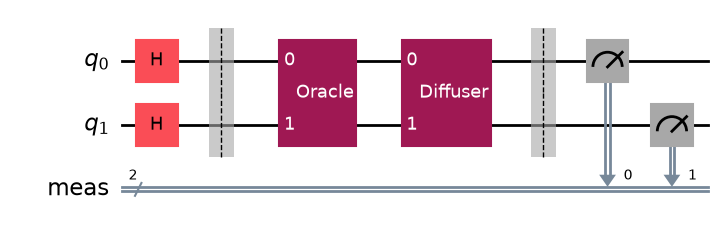

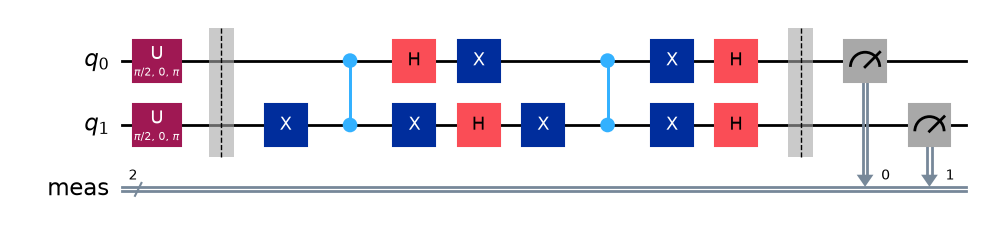

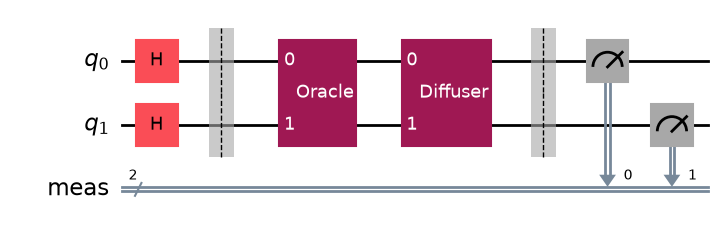

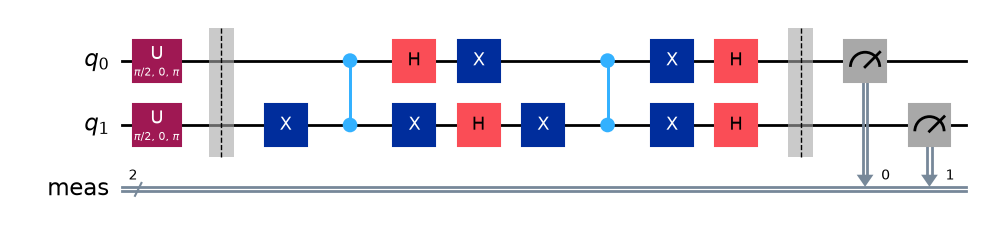

In [6]:
grover2 = QuantumCircuit(2)
grover2.h([0, 1])                                       # 1. superposition
grover2.barrier()
grover2.append(two_qubit_oracle(secret).to_gate(), [0, 1])  # 2. oracle (knows the secret)
grover2.append(two_qubit_diffuser().to_gate(), [0, 1])      # 3. diffuser
grover2.measure_all()                                   # 4. measurement

display(grover2.draw('mpl'))
grover2.decompose().draw('mpl')

### Code: run it and read the answer

**What this cell does.** It runs `grover2` 1024 times (`shots`) on the local simulator and finds the most frequent outcome.

- `execute(...).result().get_counts()` returns a dictionary such as `{'10': 1024}`, mapping each bitstring to how many times it was measured.
- `max(counts, key=counts.get)` picks the bitstring with the **highest count**.
  (The original notebook used a hand-written loop here that never updated its running maximum, so it always returned the last key. Using `max(...)` avoids that bug.)
- `seed_simulator=7` makes the run reproducible.

On a perfect simulator, **all 1024 shots** should land on the secret position.

Counts: {'01': 1024}
Grover's algorithm says the card is at position 2 (bitstring '01')


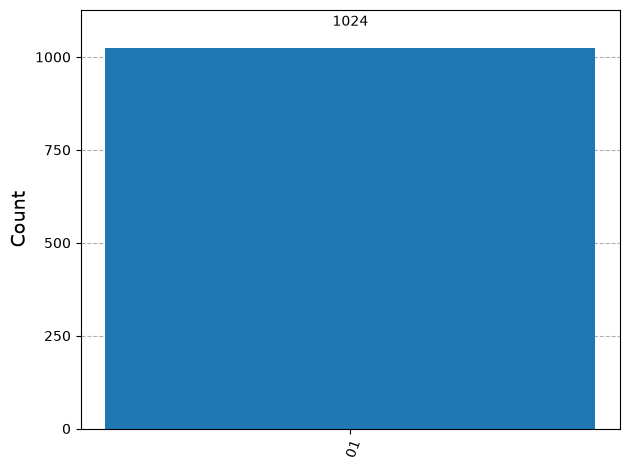

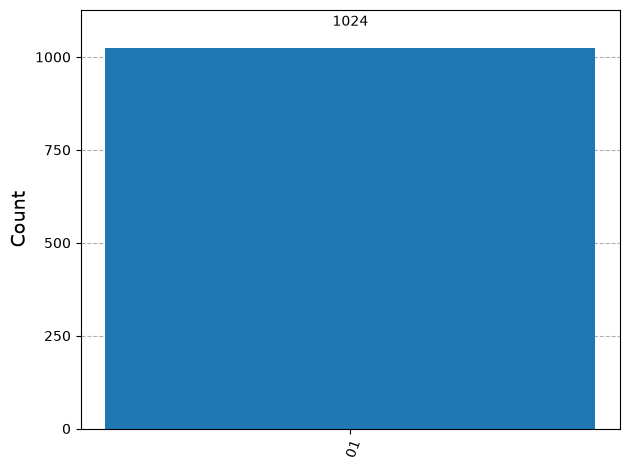

In [7]:
counts = execute(grover2, backend, shots=1024, seed_simulator=7).result().get_counts()
found = max(counts, key=counts.get)

print("Counts:", counts)
print(f"Grover's algorithm says the card is at position {positions.index(found) + 1} (bitstring '{found}')")
plot_histogram(counts)

### Code: reveal the secret and check

**What this cell does.** It prints the secret chosen earlier so you can confirm that Grover found it **with one oracle query**. A classical search needs 2.25 queries on average.

It also computes the exact final state with `Statevector`. That removes sampling noise and shows that the probability of the secret is exactly 1.0. Re-run the "hide" cell and the cells after it a few times: the answer is always correct.

In [8]:
print(f"The hidden position was: {positions.index(secret) + 1} (bitstring '{secret}')")
print("Correct!" if found == secret else "Mismatch?!")

exact = Statevector(grover2.remove_final_measurements(inplace=False)).probabilities_dict()
print("Exact probabilities:", {str(k): round(float(v), 6) for k, v in exact.items()})

The hidden position was: 2 (bitstring '01')
Correct!
Exact probabilities: {'00': 0.0, '01': 1.0, '10': 0.0, '11': 0.0}


## 5. Watching the amplitudes move (statevector view)

Histograms only show the **end** result. To really understand Grover, we look **inside** the circuit after each stage and plot the amplitudes, just like the bar pictures in section 2.5. We use 3 qubits ($N=8$) with one marked state, `101`.

### Code: helper to plot amplitudes after each stage

**What this cell does.** It defines `plot_amplitude_stages(...)`, which:
1. takes a list of `(label, circuit)` pairs, where each circuit is the algorithm **up to** a certain stage;
2. computes the exact `Statevector` of each circuit;
3. draws one bar chart per stage: one bar per basis state, the marked state in red, and a dashed line for the **mean amplitude** $\bar a$.

Grover only ever produces **real** amplitudes, so we plot `np.real(...)`.

**Global phase.** Our diffuser really implements $I - 2|s\rangle\langle s|$, which is $-U_s$. The extra $-1$ multiplies the *whole* state, so it never affects measurement. But it would make every bar flip upside down. For readability we multiply by $-1$ wherever the `flip_global_phase` flag is set.

In [9]:
def plot_amplitude_stages(stages, marked, n):
    """Bar-chart the real amplitudes of each (label, circuit, flip_global_phase) stage."""
    labels = [format(i, f'0{n}b') for i in range(2**n)]
    fig, axes = plt.subplots(1, len(stages), figsize=(4.2 * len(stages), 3.2), sharey=True)
    for ax, (title, qc, flip) in zip(axes, stages):
        amps = np.real(Statevector(qc).data) * (-1 if flip else 1)
        colors = ['tab:red' if lab in marked else 'tab:blue' for lab in labels]
        ax.bar(labels, amps, color=colors)
        ax.axhline(amps.mean(), ls='--', color='gray', label=f'mean = {amps.mean():.3f}')
        ax.axhline(0, color='black', lw=0.8)
        ax.set_title(title)
        ax.tick_params(axis='x', rotation=90)
        ax.legend(loc='lower right', fontsize=8)
    axes[0].set_ylabel('amplitude')
    plt.tight_layout()
    plt.show()

### Code: one marked item out of eight, iteration by iteration

**What this cell does.** It builds the 3-qubit algorithm with the marked state `101` and plots the amplitudes at five moments:

| Stage | What you should see |
|---|---|
| after `H` | all 8 bars equal to $1/\sqrt8 \approx 0.354$ |
| after oracle (iteration 1) | the red bar is now $-0.354$; the mean drops to $\approx 0.265$ |
| after diffuser (iteration 1) | each bar is reflected about the mean ($a \to 2\bar a - a$): red jumps to $\approx 0.884$ (probability 78%), the others fall to $\approx 0.177$ |
| after oracle (iteration 2) | red flips negative again |
| after diffuser (iteration 2) | red $\approx 0.972$ (probability **94.5%**), the others almost 0 |

How the cell builds the stages:
- `mark_101` is a 3-qubit phase oracle: `X` on qubit 1 (the only `0` in `101`) turns `|101>` into `|111>`. Then `H–CCX–H` on qubit 2 acts as a CCZ, which flips the sign of `|111>`. Then `X` on qubit 1 undoes the mapping.
- `diff3` is the diffuser from section 2.4.
- `qc.compose(...)` glues circuits together, so each stage is "everything so far".

Compare these plots with the pictures in section 2.5.

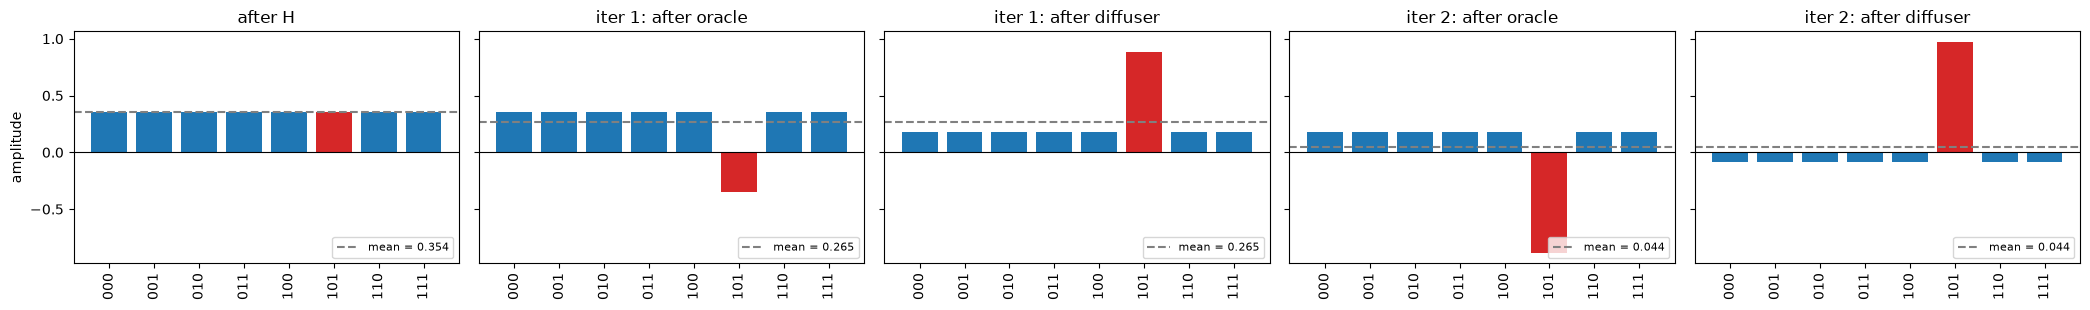

P(101) after 1 iteration : 0.7812
P(101) after 2 iterations: 0.9453


In [10]:
n3 = 3
mark_101 = QuantumCircuit(n3, name="Oracle")
mark_101.x(1)                      # |101> -> |111>
mark_101.h(2); mark_101.ccx(0, 1, 2); mark_101.h(2)   # CCZ: flip the sign of |111>
mark_101.x(1)                      # map back

diff3 = QuantumCircuit(n3, name="Diffuser")
diff3.h(range(n3)); diff3.x(range(n3))
diff3.h(2); diff3.ccx(0, 1, 2); diff3.h(2)
diff3.x(range(n3)); diff3.h(range(n3))

s0 = QuantumCircuit(n3); s0.h(range(n3))
s1 = s0.compose(mark_101)
s2 = s1.compose(diff3)
s3 = s2.compose(mark_101)
s4 = s3.compose(diff3)

plot_amplitude_stages([
    ("after H", s0, False),
    ("iter 1: after oracle", s1, False),
    ("iter 1: after diffuser", s2, True),
    ("iter 2: after oracle", s3, True),
    ("iter 2: after diffuser", s4, False),   # two global -1 phases cancel
], marked={'101'}, n=n3)

print("P(101) after 1 iteration :", round(Statevector(s2).probabilities_dict()['101'], 4))
print("P(101) after 2 iterations:", round(Statevector(s4).probabilities_dict()['101'], 4))

## 6. Three qubits, two marked states

With $N=8$ and $M=2$, $\sin\theta=\sqrt{2/8}=1/2$, so $\theta=30°$, the same angle as the 2-qubit case. **One iteration gives 100%.** We look at two different pairs of marked states.

### 6.1 Example A: mark `|101>` and `|110>` in a single compact circuit

### Code: compact circuit marking `101` and `110`

**What this cell does.** It builds the whole algorithm inline (no helper functions), so the complete gate sequence is visible in one place.

**Oracle (two `CZ` gates):**
- `cz(q2, q0)` gives $-1$ when $q_2=q_0=1$: the states `101` and `111`.
- `cz(q2, q1)` gives $-1$ when $q_2=q_1=1$: the states `110` and `111`.
- `111` is flipped **twice** and ends up unchanged. Only **`101` and `110`** keep a minus sign.

This is a nice trick: a cheap oracle built from 2-qubit gates only.

**Diffuser.** `H` on all, `X` on all, then `H–CCX–H` on $q_2$ (a CCZ), then `X` on all, `H` on all. The barriers only separate the stages in the drawing.

The circuit ends by measuring all three qubits into the classical register `cr`.

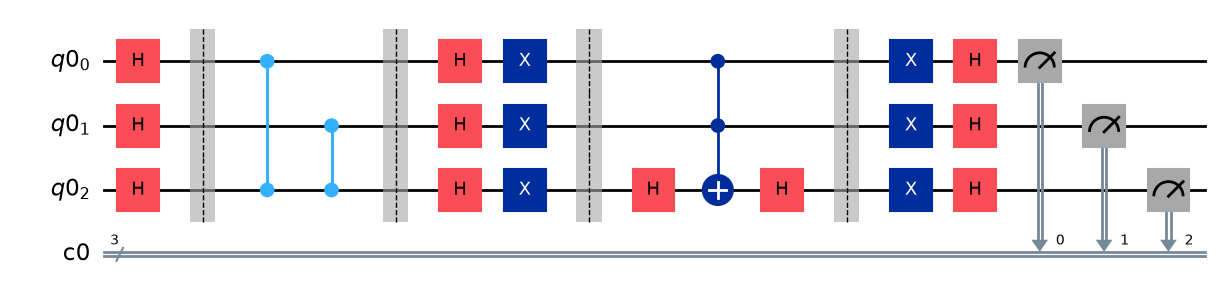

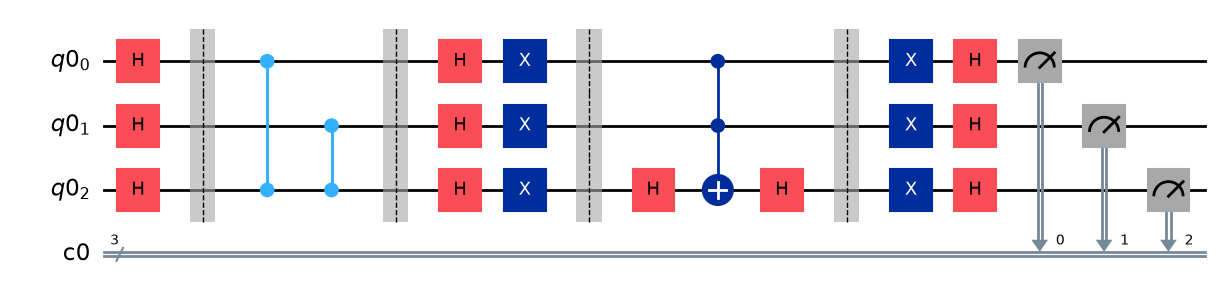

In [11]:
qr = QuantumRegister(3)     # 3 qubits
cr = ClassicalRegister(3)   # 3 classical bits to record the measurements
circuit = QuantumCircuit(qr, cr)

# Uniform superposition
circuit.h(qr)
circuit.barrier()

# Phase oracle: marks |101> and |110>
circuit.cz(qr[2], qr[0])
circuit.cz(qr[2], qr[1])
circuit.barrier()

# Diffuser (inversion about the mean)
circuit.h(qr)
circuit.x(qr)
circuit.barrier()
circuit.h(qr[2])
circuit.ccx(qr[0], qr[1], qr[2])
circuit.h(qr[2])
circuit.barrier()
circuit.x(qr)
circuit.h(qr)

# Measure
circuit.measure(qr, cr)
circuit.draw('mpl')

### Code: run Example A

**What this cell does.** It runs the circuit 1024 times and shows the histogram. Expect **only `101` and `110`**, each about 50% of the time: the two solutions are equally likely, and every other outcome has probability 0.

{'101': 526, '110': 498}


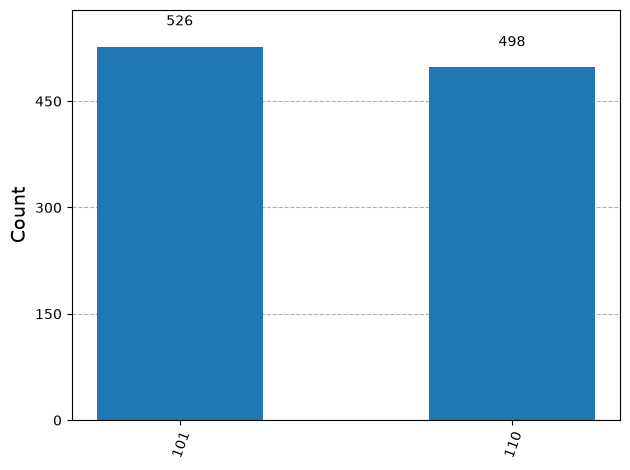

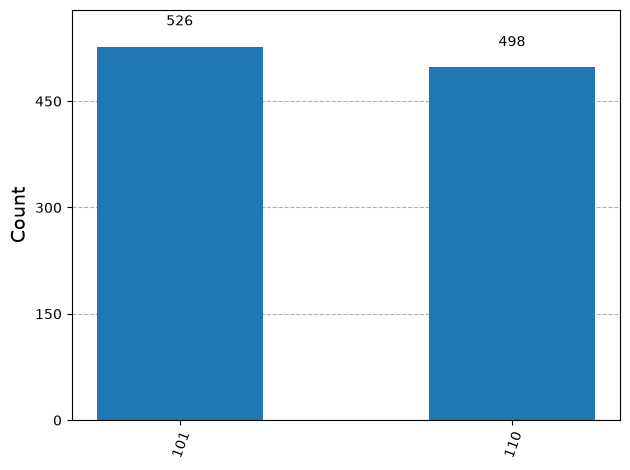

In [12]:
counts = execute(circuit, backend, shots=1024, seed_simulator=11).result().get_counts()
print(counts)
plot_histogram(counts)

### 6.2 Example B: mark `|000>` and `|111>`, built from reusable functions

Now we split the algorithm into named functions: **oracle**, **multi-controlled Z**, and **inversion about the average**. This is how larger Grover circuits are written in practice.

### Code: phase oracle for `000` and `111`

**What this cell does.** It defines `get_phase_oracle_circuit(circuit, register)` and draws it.

It is a good example of a **global phase** at work. The gates are:
- `Z` on every qubit, giving a factor $(-1)^{x_0+x_1+x_2}$;
- `CZ(2,0)`, `CZ(2,1)`, `CZ(1,0)`, giving a factor $(-1)^{x_0x_2 + x_1x_2 + x_0x_1}$.

Adding up the exponents mod 2 for each basis state:

| state | $\sum x_i$ | $\sum x_ix_j$ | total | sign |
|---|---|---|---|---|
| 000 | 0 | 0 | 0 | + |
| one 1 (e.g. 001) | 1 | 0 | 1 | − |
| two 1s (e.g. 011) | 2 | 1 | 3 | − |
| 111 | 3 | 3 | 6 | + |

So the oracle puts a $-1$ on the **six** states other than `000` and `111`. That is the same as putting $-1$ on `000` and `111`, multiplied by a global phase of $-1$, which can never be observed. So in effect, **`000` and `111` are marked**.

The function uses its `register` argument. The original version used a global variable `qr` by mistake, which only worked by coincidence.

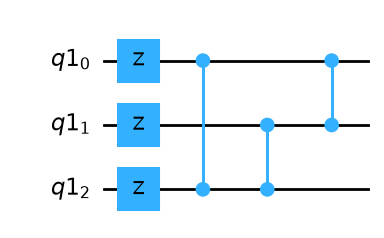

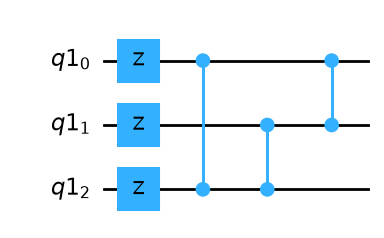

In [13]:
def get_phase_oracle_circuit(circuit, register):
    """Phase oracle that (up to a global phase) marks |000> and |111>."""
    circuit.z(register)                       # (-1)^(x0 + x1 + x2)
    circuit.cz(register[2], register[0])      # (-1)^(x0*x2)
    circuit.cz(register[2], register[1])      # (-1)^(x1*x2)
    circuit.cz(register[1], register[0])      # (-1)^(x0*x1)

qr = QuantumRegister(3)
oracleCircuit = QuantumCircuit(qr)
get_phase_oracle_circuit(oracleCircuit, qr)
oracleCircuit.draw(output="mpl")

### Code: verify the oracle's phases

**What this cell does.** It checks the claim above **numerically**. For each basis state $|x\rangle$ we prepare it, apply the oracle, and read the sign of the resulting amplitude.

- `Statevector.from_label(label)` prepares the basis state, e.g. `'011'`.
- `.evolve(oracleCircuit)` applies the oracle.
- The amplitude of $|x\rangle$ after the oracle is $\pm1$, and we print that sign.

You should see `+1` for `000` and `111` and `-1` for the rest, which confirms the table.

> This kind of check is a good habit. An oracle that does not do what you think is the most common reason a Grover circuit "doesn't work".

In [14]:
for label in [format(i, '03b') for i in range(8)]:
    out = Statevector.from_label(label).evolve(oracleCircuit)
    sign = np.real(out.data[int(label, 2)])
    print(f"|{label}>  ->  {sign:+.0f} |{label}>")

|000>  ->  +1 |000>
|001>  ->  -1 |001>
|010>  ->  -1 |010>
|011>  ->  -1 |011>
|100>  ->  -1 |100>
|101>  ->  -1 |101>
|110>  ->  -1 |110>
|111>  ->  +1 |111>


### Code: multi-controlled Z and inversion about the average

**What this cell does.** It defines the two building blocks of the diffuser.

**`n_controlled_Z(circuit, controls, target)`** applies a $Z$ to `target` only if **all** `controls` are $|1\rangle$:
- It surrounds a multi-controlled X with `H` gates on the target, because $HXH = Z$.
- `mcx` (multi-controlled X) works for **any** number of controls. With 1 control it is a `CX`, with 2 it is a Toffoli (`CCX`). The original version only supported up to 2 controls; `mcx` removes that limit.

**`inversion_about_average(circuit, register, n)`** is the diffuser $U_s$ from section 2.4:
1. `H` on all qubits takes $|s\rangle$ to $|0\dots0\rangle$;
2. `X` on all qubits takes $|0\dots0\rangle$ to $|1\dots1\rangle$;
3. the multi-controlled Z flips the sign of $|1\dots1\rangle$, i.e. of the original $|s\rangle$ direction;
4. `X` and `H` undo steps 2 and 1.

The net effect is a reflection about $|s\rangle$, which is inversion about the mean.

In [15]:
def n_controlled_Z(circuit, controls, target):
    """Z on `target`, controlled on all qubits in `controls` (any number of controls)."""
    circuit.h(target)
    circuit.mcx(controls, target)
    circuit.h(target)

def inversion_about_average(circuit, register, n):
    """Apply the diffuser (inversion about the average) on the first n qubits of `register`."""
    circuit.h(register)
    circuit.x(register)
    n_controlled_Z(circuit, [register[j] for j in range(n - 1)], register[n - 1])
    circuit.x(register)
    circuit.h(register)

### Code: draw the diffuser

**What this cell does.** It draws the inversion-about-the-average circuit for 3 qubits. You should see `H`, `X`, then `H`–Toffoli–`H` on the last qubit, then `X` and `H`. Compare it with the diffuser in Example A: they are the same circuit.

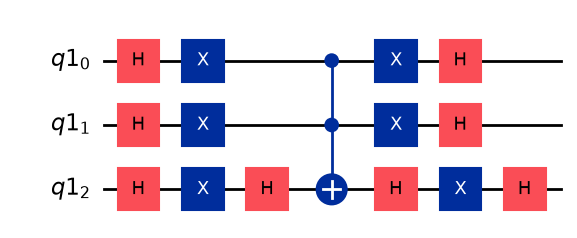

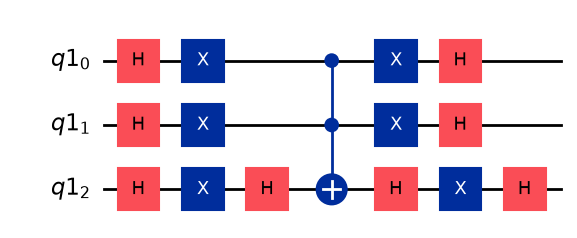

In [16]:
qAverage = QuantumCircuit(qr)
inversion_about_average(qAverage, qr, 3)
qAverage.draw(output='mpl')

### Code: assemble the complete circuit for Example B

**What this cell does.** It combines the pieces into `groverCircuit`:
1. `h(qr)`: uniform superposition;
2. `get_phase_oracle_circuit`: marks `000` and `111`;
3. `inversion_about_average`: the diffuser;
4. `measure`: read out all 3 qubits.

As before, $M=2$ out of $N=8$, so **one iteration** is optimal.

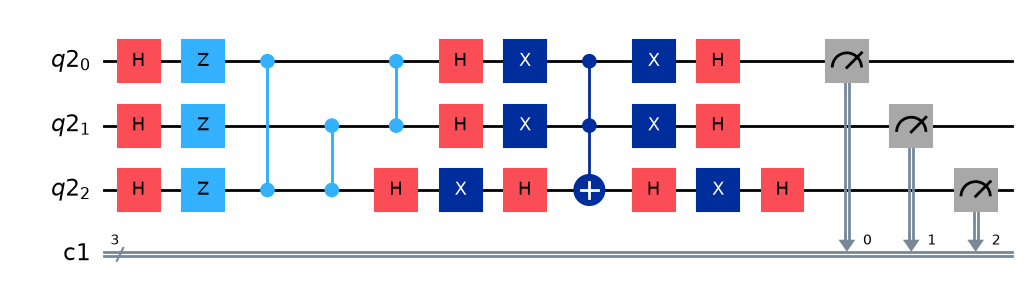

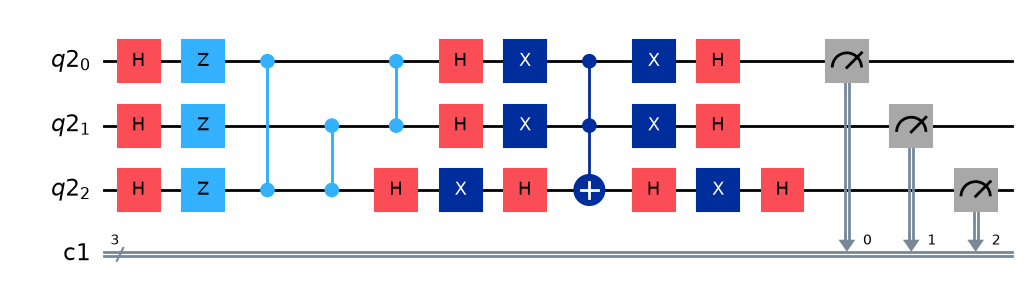

In [17]:
qr = QuantumRegister(3)
cr = ClassicalRegister(3)

groverCircuit = QuantumCircuit(qr, cr)
groverCircuit.h(qr)

get_phase_oracle_circuit(groverCircuit, qr)
inversion_about_average(groverCircuit, qr, 3)

groverCircuit.measure(qr, cr)
groverCircuit.draw(output="mpl")

### Code: run Example B on the simulator

**What this cell does.** It runs `groverCircuit` for 1024 shots. Expect only **`000` and `111`**, about 50% each. The algorithm has found both marked states.

{'000': 466, '111': 558}


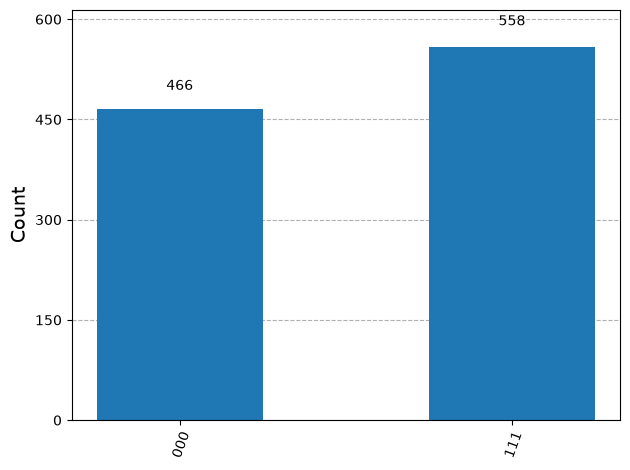

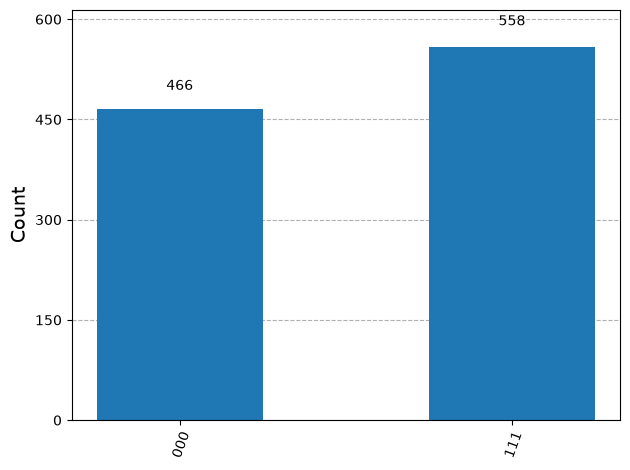

In [18]:
counts = execute(groverCircuit, backend, shots=1024, seed_simulator=13).result().get_counts()
print(counts)
plot_histogram(counts)

## 7. General $n$-qubit Grover and the optimal number of iterations

So far every example needed exactly one iteration. Now we write Grover for **any** $n$ and **any** set of marked states, and test the formula from section 2.6: $P(k)=\sin^2((2k+1)\theta)$.

### Code: general oracle, diffuser and circuit builder

**What this cell does.** It defines four functions that together form a complete, general Grover implementation.

**`phase_oracle(n, marked)`** marks every bitstring in the list `marked`. For each target it uses the same "X–MCZ–X sandwich" as before:
- `X` on each qubit whose bit is `0`, so the target becomes $|1\dots1\rangle$;
- a multi-controlled Z, which flips the sign of $|1\dots1\rangle$;
- `X` again to undo the mapping.

Each sandwich flips the sign of exactly one state, so applying one per target marks all of them.

**`diffuser(n)`** is the general inversion about the mean (section 2.4).

**`optimal_iterations(n, m)`** implements $k_{\text{opt}} = \lfloor \pi / (4\theta) \rfloor$ with $\theta = \arcsin\sqrt{m/2^n}$.

**`grover_circuit(n, marked, iterations, measure=True)`** builds the full algorithm: `H` on all qubits, then `iterations` repetitions of (oracle, diffuser), then an optional measurement. With `measure=False` we can take its exact `Statevector`.

The last line prints $k_{\text{opt}}$ for a few problem sizes. Note how slowly it grows: roughly $\sqrt N$.

In [19]:
def phase_oracle(n, marked):
    """Phase oracle on n qubits flipping the sign of every bitstring in `marked` (Qiskit order)."""
    qc = QuantumCircuit(n, name="Oracle")
    for target in marked:
        zeros = [q for q, bit in enumerate(reversed(target)) if bit == '0']
        if zeros:
            qc.x(zeros)
        n_controlled_Z(qc, list(range(n - 1)), n - 1)
        if zeros:
            qc.x(zeros)
    return qc

def diffuser(n):
    """Inversion about the mean on n qubits."""
    qc = QuantumCircuit(n, name="Diffuser")
    inversion_about_average(qc, list(range(n)), n)
    return qc

def optimal_iterations(n, m=1):
    """floor(pi / (4 theta)) with sin(theta) = sqrt(m / 2**n)."""
    theta = asin(sqrt(m / 2**n))
    return floor(pi / (4 * theta))

def grover_circuit(n, marked, iterations, measure=True):
    """Full Grover circuit: H^n, then `iterations` x (oracle, diffuser)."""
    qc = QuantumCircuit(n)
    qc.h(range(n))
    oracle_gate = phase_oracle(n, marked).to_gate()
    diffuser_gate = diffuser(n).to_gate()
    for _ in range(iterations):
        qc.append(oracle_gate, range(n))
        qc.append(diffuser_gate, range(n))
    if measure:
        qc.measure_all()
    return qc

for n in (2, 3, 4, 5, 8, 10, 20):
    print(f"n = {n:2d}  (N = {2**n:>8,})  ->  k_opt = {optimal_iterations(n)}")

n =  2  (N =        4)  ->  k_opt = 1
n =  3  (N =        8)  ->  k_opt = 2
n =  4  (N =       16)  ->  k_opt = 3
n =  5  (N =       32)  ->  k_opt = 4
n =  8  (N =      256)  ->  k_opt = 12
n = 10  (N =    1,024)  ->  k_opt = 25
n = 20  (N = 1,048,576)  ->  k_opt = 804


### Code: success probability vs number of iterations (theory vs simulation)

**What this cell does.** It runs the most important experiment in the notebook. For $n=5$ ($N=32$) it sweeps the number of iterations $k = 0 \dots 14$ and plots the probability of measuring a marked state, for two cases:
- **$M=1$** (marked: `10110`), where $k_{\text{opt}} = 4$;
- **$M=4$** (four marked states), where $k_{\text{opt}} = 2$.

For each $k$:
- the **solid line** is the theory, $\sin^2((2k+1)\theta)$;
- the **dots** are the exact simulation: the circuit is built with `grover_circuit(..., measure=False)`, and the probabilities of the marked states are added up from its `Statevector`.

**What to look for:**
1. The dots sit exactly on the curves, confirming the rotation picture.
2. The peak is at $k_{\text{opt}}$ (marked by the dotted lines).
3. **Over-rotation**: after the peak, the probability *falls*. At about $2k_{\text{opt}}$ it is close to 0, and then it rises again. Running "as long as possible" is the wrong strategy for Grover.
4. More marked states means a faster rotation and an earlier peak.

M = 1: k_opt = 4,  P(success at k_opt) = 0.9992
M = 4: k_opt = 2,  P(success at k_opt) = 0.9453


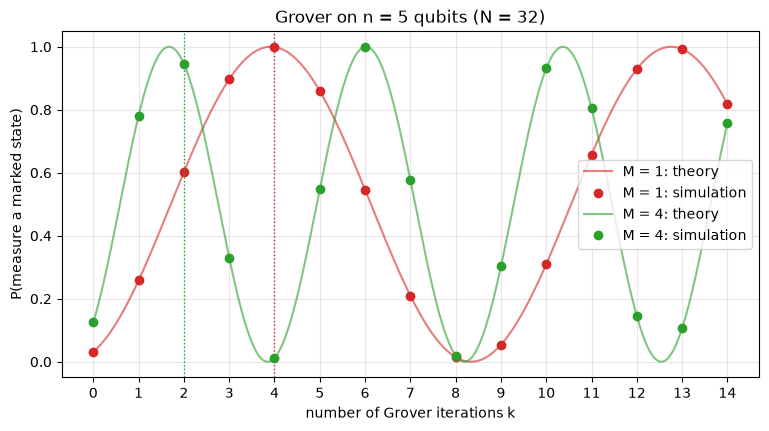

In [20]:
n = 5
cases = {
    "M = 1": ['10110'],
    "M = 4": ['00011', '01100', '10101', '11110'],
}
ks = np.arange(0, 15)

plt.figure(figsize=(9, 4.5))
for (name, marked), color in zip(cases.items(), ['tab:red', 'tab:green']):
    theta = asin(sqrt(len(marked) / 2**n))
    k_fine = np.linspace(0, ks[-1], 400)
    plt.plot(k_fine, np.sin((2 * k_fine + 1) * theta) ** 2, color=color, alpha=0.6,
             label=f"{name}: theory")
    sim = []
    for k in ks:
        probs = Statevector(grover_circuit(n, marked, k, measure=False)).probabilities_dict()
        sim.append(sum(probs.get(m, 0) for m in marked))
    plt.plot(ks, sim, 'o', color=color, label=f"{name}: simulation")
    k_opt = optimal_iterations(n, len(marked))
    plt.axvline(k_opt, color=color, ls=':', lw=1)
    print(f"{name}: k_opt = {k_opt},  P(success at k_opt) = {sim[k_opt]:.4f}")

plt.xlabel("number of Grover iterations k")
plt.ylabel("P(measure a marked state)")
plt.title(f"Grover on n = {n} qubits (N = {2**n})")
plt.xticks(ks)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Code: sampled run at the optimal number of iterations

**What this cell does.** It builds the $n=5$, $M=1$ circuit with $k_{\text{opt}}=4$ iterations, measures it 2048 times, and plots the histogram. The marked state `10110` should collect about **99.9%** of the shots. A classical search would need about 16 queries on average; Grover used 4.

4 iterations -> most frequent outcome: 10110  (2046/2048 shots)


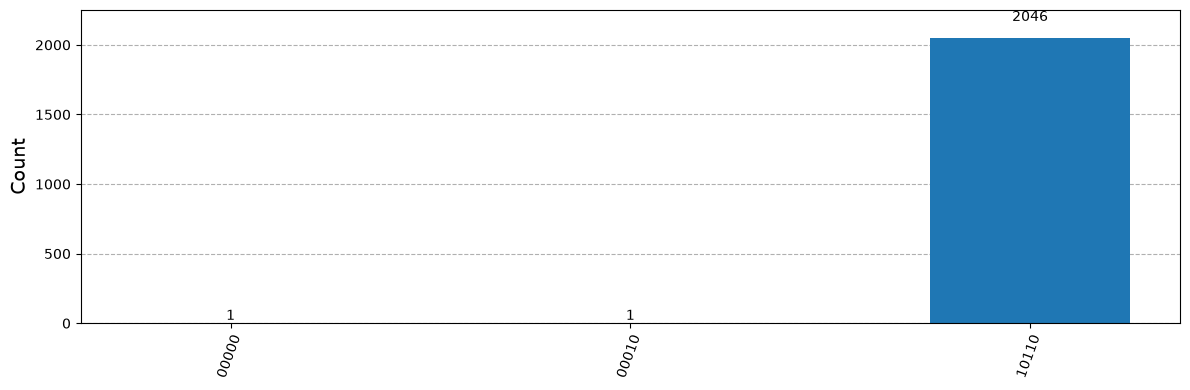

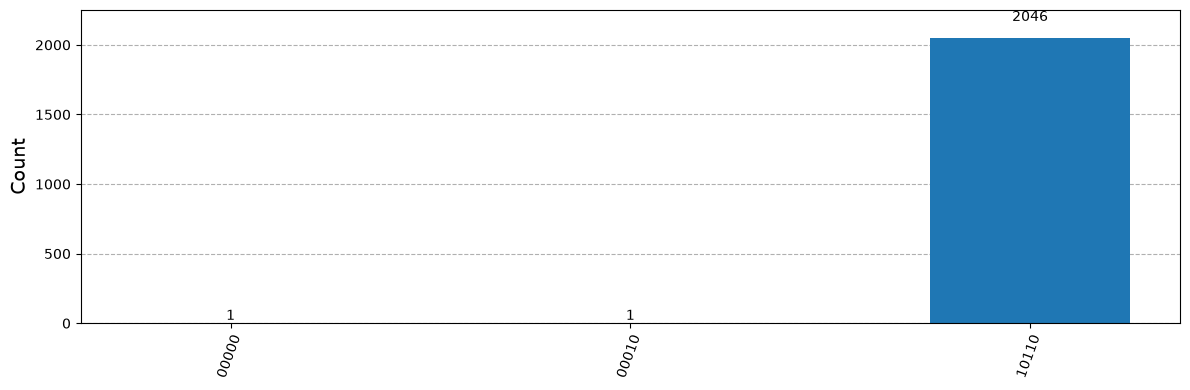

In [21]:
marked = ['10110']
k_opt = optimal_iterations(5, len(marked))
qc5 = grover_circuit(5, marked, k_opt)
counts = execute(qc5, backend, shots=2048, seed_simulator=17).result().get_counts()
print(f"{k_opt} iterations -> most frequent outcome: {max(counts, key=counts.get)}  "
      f"({counts.get(marked[0], 0)}/2048 shots)")
plot_histogram(counts, figsize=(12, 4))

## 8. Building an oracle from Boolean logic: 3-SAT by hand

Up to now we built oracles by *already knowing* the answer, e.g. "mark `101`". That is fine for learning, but useless in practice. In a real problem, the oracle **checks a condition** without knowing which input satisfies it.

A classic example is **3-SAT**: given a formula in conjunctive normal form, with clauses of 3 literals joined by AND, is there an assignment of the variables that makes it true? (3-SAT is NP-complete.) Grover can search the $2^n$ assignments in about $\sqrt{2^n}$ oracle calls.

To build such an oracle we need **reversible** (quantum) versions of the logic gates AND and OR.

### 8.1 Quantum AND and OR gates
- **AND**: a Toffoli gate `CCX(w, x, t)` flips the target `t` (starting at 0) exactly when $w=x=1$, so `t = w AND x`.
- **OR**: De Morgan's law, $w \lor x = \lnot(\lnot w \land \lnot x)$. So we negate the inputs with `X`, apply a Toffoli onto a target pre-set to 1 (with an `X`), and un-negate the inputs. The target ends up holding `w OR x`.
- A **3-input** gate is two 2-input gates chained together through a temporary ("ancilla") qubit.

Every gate also has a **reverse** (inverse) version. It *uncomputes* the temporary results, returning the ancillas to $|0\rangle$. We will see why this matters shortly.

### Code: reversible AND / OR building blocks

**What this cell does.** It defines the logic gates used to build the 3-SAT oracle. Every function takes the register `qr`, the circuit `qc`, and **qubit indices**. It adds gates to `qc` and returns the index of the qubit that holds the result.

| Function | Effect |
|---|---|
| `setup_input(qr, qc, a, b, c, d)` | prepares a classical input by applying `X` to qubits whose value is 1 (`d` goes on qubit 4, because qubit 3 is a temporary in the 3-input tests) |
| `quantumand_2(w, x, t1)` | `t1 ^= w AND x` (one Toffoli). It is its **own inverse**: applying it twice restores `t1` |
| `quantumand_3(w, x, y, t1, t2)` | `t1 = w AND x`, then `t2 = y AND t1` |
| `quantumor_2(w, x, t1)` | `t1 = w OR x` using De Morgan: `X` on the inputs and the target, Toffoli, then `X` to restore the inputs |
| `quantumor_2_reverse` | the same gates in reverse order: uncomputes `t1` back to 0 |
| `quantumor_3(w, x, y, t1, t2)` | `t1 = w OR x`, then `t2 = y OR t1` |
| `quantumor_3_reverse` | uncomputes both `t2` and `t1` |

Notice the pattern in the `_reverse` functions: **the same gates in the opposite order**. Every gate here is its own inverse, so reversing the sequence undoes the whole computation.

In [22]:
def setup_input(qr,qc,a,b,c,d=None):
    if a:
        qc.x(qr[0])
    if b:
        qc.x(qr[1])
    if c:
        qc.x(qr[2])
    if d:
        qc.x(qr[4])

def quantumand_3(qr,qc,w,x,y,t1,t2):
    qc.ccx(qr[w],qr[x],qr[t1])
    qc.ccx(qr[y],qr[t1],qr[t2])
    return t2


def quantumand_2(qr,qc,w,x,t1):
    qc.ccx(qr[w],qr[x],qr[t1])
    return t1

def quantumor_2(qr,qc,w,x,t1):
    qc.x(qr[w])
    qc.x(qr[x])
    qc.x(qr[t1])
    qc.ccx(qr[w],qr[x],qr[t1])
    qc.x(qr[w])
    qc.x(qr[x])
    return t1

def quantumor_2_reverse(qr,qc,w,x,t1):
    qc.x(qr[x])
    qc.x(qr[w])
    qc.ccx(qr[w],qr[x],qr[t1])
    qc.x(qr[t1])
    qc.x(qr[x])
    qc.x(qr[w])
    return t1

def quantumor_3(qr,qc,w,x,y,t1,t2):
    qc.x(qr[w])
    qc.x(qr[x])
    qc.x(qr[t1])
    qc.ccx(qr[w],qr[x],qr[t1])
    qc.x(qr[w])
    qc.x(qr[x])

    qc.x(qr[y])
    qc.x(qr[t1])
    qc.x(qr[t2])
    qc.ccx(qr[y],qr[t1],qr[t2])
    qc.x(qr[y])
    qc.x(qr[t1])
    return t2

def quantumor_3_reverse(qr,qc,w,x,y,t1,t2):
    qc.x(qr[t1])
    qc.x(qr[y])
    qc.ccx(qr[y],qr[t1],qr[t2])
    qc.x(qr[t2])
    qc.x(qr[t1])
    qc.x(qr[y])
    
    qc.x(qr[x])
    qc.x(qr[w])
    qc.ccx(qr[w],qr[x],qr[t1])
    qc.x(qr[t1])
    qc.x(qr[x])
    qc.x(qr[w])
    return t2

### Code: test the logic gates with truth tables

**What this cell does.** It checks every gate on **every** possible classical input and prints a truth table.

- `run_local_sim_one_result(qc)` runs a circuit **once** (`shots=1`; the inputs are classical, so the result is deterministic) and returns the measured bits **reversed**, so that qubit 0 comes first and the output reads in the natural order $a, b, c$.
- `test_logic_function_2(f, frev)` loops over all 8 inputs `abc` (with `c` the target, starting at 0) and prints:
  - **forward**: the qubits after applying `f`; the last bit is the result, e.g. `a AND b`;
  - **reverse**: the qubits after applying `f` and then `frev`; this should equal the input again.
- `test_logic_function_3` does the same with 4 inputs on 5 qubits (qubit 3 is the temporary). It removes the temporary from the printout.

**How to read the output.** For "two qubit quantum AND" with input `110`, forward should be `111` (since $1 \land 1 = 1$) and reverse should be `110` again. Check a few rows by hand.

In [23]:
import itertools
def run_local_sim_one_result(qc):
    job_exp = execute(qc, backend=backend, shots=1)
    result = job_exp.result()
    final=result.get_counts(qc)
    result_in_order=list(final.keys())[0][::-1]
    return result_in_order

def test_logic_function_2(f,frev):
    print("inputs","forward","reverse")
    print("abc","a'b'c'","a''b''c''")
    for combo in itertools.product([0,1],repeat=3):
        # forward
        qr = QuantumRegister(3)
        cr = ClassicalRegister(3)
        qc = QuantumCircuit(qr,cr)
        setup_input(qr,qc,combo[0],combo[1],combo[2])
        f(qr,qc,0,1,2)
        for i in range(3):
            qc.measure(qr[i],cr[i])
        forward_result=run_local_sim_one_result(qc)
        # forward then reverse
        qr = QuantumRegister(3)
        cr = ClassicalRegister(3)
        qc = QuantumCircuit(qr,cr)
        setup_input(qr,qc,combo[0],combo[1],combo[2])
        f(qr,qc,0,1,2)
        frev(qr,qc,0,1,2)
        for i in range(3):
            qc.measure(qr[i],cr[i])
        reverse_result=run_local_sim_one_result(qc)
        print('%d%d%d %s %s'%(combo[0],combo[1],combo[2],forward_result,reverse_result))

        

def test_logic_function_3(f,frev):
    print("inputs","forward","reverse")
    print("abcd","a'b'c'd'","a''b''c''d''")
    for combo in itertools.product([0,1],repeat=4):
        # forward
        qr = QuantumRegister(5)
        cr = ClassicalRegister(5)
        qc = QuantumCircuit(qr,cr)
        setup_input(qr,qc,combo[0],combo[1],combo[2],combo[3])
        f(qr,qc,0,1,2,3,4)
        for i in range(5):
            qc.measure(qr[i],cr[i])
        forward_result=run_local_sim_one_result(qc)
        # forward then reverse
        qr = QuantumRegister(5)
        cr = ClassicalRegister(5)
        qc = QuantumCircuit(qr,cr)
        setup_input(qr,qc,combo[0],combo[1],combo[2],combo[3])
        f(qr,qc,0,1,2,3,4)
        frev(qr,qc,0,1,2,3,4)
        for i in range(5):
            qc.measure(qr[i],cr[i])
        reverse_result=run_local_sim_one_result(qc)
        
        forward_result=forward_result[0:3]+forward_result[4]
        reverse_result=reverse_result[0:3]+reverse_result[4]

        print('%d%d%d%d %s %s'%(combo[0],combo[1],combo[2],combo[3],forward_result,reverse_result))

print("Testing two qubit quantum AND")
test_logic_function_2(quantumand_2,quantumand_2)
print()

print("Testing two qubit quantum OR")
test_logic_function_2(quantumor_2,quantumor_2_reverse)
print()

print("Testing three qubit quantum AND")
test_logic_function_3(quantumand_3,quantumand_3)
print()

print("Testing three qubit quantum OR")
test_logic_function_3(quantumor_3,quantumor_3_reverse)


    

Testing two qubit quantum AND
inputs forward reverse
abc a'b'c' a''b''c''
000 000 000
001 001 001
010 010 010
011 011 011
100 100 100
101 101 101
110 111 110
111 110 111

Testing two qubit quantum OR
inputs forward reverse
abc a'b'c' a''b''c''
000 000 000
001 001 001
010 011 010
011 010 011
100 101 100
101 100 101
110 111 110
111 110 111

Testing three qubit quantum AND
inputs forward reverse
abcd a'b'c'd' a''b''c''d''
0000 0000 0000
0001 0001 0001
0010 0010 0010
0011 0011 0011
0100 0100 0100
0101 0101 0101
0110 0110 0110
0111 0111 0111
1000 1000 1000
1001 1001 1001
1010 1010 1010
1011 1011 1011
1100 1100 1100
1101 1101 1101
1110 1111 1111
1111 1110 1110

Testing three qubit quantum OR
inputs forward reverse
abcd a'b'c'd' a''b''c''d''
0000 0000 0000
0001 0001 0001
0010 0011 0010
0011 0010 0011
0100 0101 0100
0101 0100 0101
0110 0111 0110
0111 0110 0111
1000 1001 1000
1001 1000 1001
1010 1011 1010
1011 1010 1011
1100 1101 1100
1101 1100 1101
1110 1111 1110
1111 1110 1111


### 8.2 Our 3-SAT problem

$$(a \lor b \lor \neg c) \land (a \lor b \lor c) \land (a \lor \neg b \lor c) \land (a \lor \neg b \lor \neg c) \land (\neg a \lor b \lor \neg c) \land (\neg a \lor b \lor c) \land (\neg a \lor \neg b \lor \neg c)$$

There are 7 clauses on 3 variables. Each clause rules out exactly one of the 8 assignments; for example, $(a \lor b \lor \neg c)$ is false only when $a=0, b=0, c=1$. Seven assignments are ruled out, so **exactly one** satisfies the formula.

### Code: classical truth table of the formula

**What this cell does.** It evaluates the formula with ordinary Python Booleans for all 8 inputs. This is our **reference answer**: the quantum oracle must agree with it. Only `(1, 1, 0)`, i.e. $a=1, b=1, c=0$, should print `1`.

`itertools.product([0,1], repeat=3)` generates all 8 combinations `(0,0,0) … (1,1,1)`.

In [24]:
def _3sat_mystery3_classical(a,b,c):
    return int((a or b or not c) and (a or b or c) and (a or not b or c) and (a or not b or not c) and (not a or b or not c)  and (not a or b or c) and (not a or not b or not c) )
for combo in itertools.product([0,1],repeat=3):
    print(combo,'->',_3sat_mystery3_classical(combo[0],combo[1], combo[2]))

(0, 0, 0) -> 0
(0, 0, 1) -> 0
(0, 1, 0) -> 0
(0, 1, 1) -> 0
(1, 0, 0) -> 0
(1, 0, 1) -> 0
(1, 1, 0) -> 1
(1, 1, 1) -> 0


### Code: negating literals

**What this cell does.** It defines `setup_or_teardown_logic(qr, qc, is_a, is_b, is_c)`. A clause like $(a \lor \neg b \lor c)$ needs $\neg b$. We get it by applying `X` to qubit 1 **before** the OR, and applying `X` again **after** it to restore $b$.

The arguments say which variables are used **as is** (`True`) and which are **negated** (`False`). The same function is called before a clause (setup) and after it (teardown), because `X` is its own inverse.

In [25]:
def setup_or_teardown_logic(qr,qc,is_a,is_b,is_c): 
    """    
    is_a,is_b,and is_c: False indicates the variable should be negated, True left as is.
    Negation is done with the X gate.

    """    
    if not is_a:
        qc.x(qr[0])
    if not is_b:
        qc.x(qr[1])
    if not is_c:
        qc.x(qr[2])

### Code: the 3-SAT oracle circuit (23 qubits)

**What this cell does.** It defines `_3sat_mystery_3(qr, qc, reverse, full_reverse)`, which computes the whole formula into qubit 22.

**Qubit layout:**

| Qubits | Role |
|---|---|
| 0, 1, 2 | inputs $a, b, c$ |
| 3–16 | 7 clauses × 2 ancillas each; the second ancilla of each pair (4, 6, 8, …, 16) holds that clause's value |
| 17, 18, 19 | ANDs of clause pairs (1∧2), (3∧4), (5∧6) |
| 20, 21 | (1∧2∧3∧4) and (5∧6∧7) |
| 22 | final result = AND of everything |

**Structure:**
1. **Compute.** For each clause: negate the right literals, apply `quantumor_3` into its two ancillas, un-negate.
2. **Whittle down.** A tree of `quantumand_2` gates combines the 7 clause results into a single bit on qubit 22.
3. **Uncompute** (if `reverse=True`). Run steps 2 and 1 **backwards** to return every ancilla to $|0\rangle$.
   - `full_reverse=True` also uncomputes qubit 22, so *everything* returns to 0. That is useful only for testing.
   - `full_reverse=False` keeps the result on qubit 22 and cleans up everything else. **This is the mode Grover needs.**

**Why uncompute?** Leftover ancillas would stay **entangled** with the inputs. The marked and unmarked branches of the superposition would then differ in the ancilla qubits too, and the diffuser's interference would no longer work. A clean oracle must leave *only* the phase (or the result bit) behind.

In [26]:
def _3sat_mystery_3(qr,qc,reverse=True,full_reverse=False):
    # w,x,y in registers 0,1,2. 
    # Everything else can be temp/results
    # General pattern
    # 1. setup logic (which of a,b,c are negated)
    # 2. execute computation
    # 3. reverse logic so that we are back to a,b,c without negations
    # If this circuit is doing its job, should only be satisfied by 110

    # (a or b or not c)
    setup_or_teardown_logic(qr,qc,True,True,False)
    first_clause=quantumor_3(qr,qc,0,1,2,3,4)
    setup_or_teardown_logic(qr,qc,True,True,False)

    # (a or b or c) 
    setup_or_teardown_logic(qr,qc,True,True,True)
    second_clause=quantumor_3(qr,qc,0,1,2,5,6)
    setup_or_teardown_logic(qr,qc,True,True,True)

    # (a or not b or c)
    setup_or_teardown_logic(qr,qc,True,False,True)
    third_clause=quantumor_3(qr,qc,0,1,2,7,8)
    setup_or_teardown_logic(qr,qc,True,False,True)

    # (a or not b or not c)
    setup_or_teardown_logic(qr,qc,True,False,False)
    fourth_clause=quantumor_3(qr,qc,0,1,2,9,10)
    setup_or_teardown_logic(qr,qc,True,False,False)

    # (not a or b or not c) 
    setup_or_teardown_logic(qr,qc,False,True,False)
    fifth_clause=quantumor_3(qr,qc,0,1,2,11,12)
    setup_or_teardown_logic(qr,qc,False,True,False)

    # (not a or b or c)
    setup_or_teardown_logic(qr,qc,False,True,True)
    sixth_clause=quantumor_3(qr,qc,0,1,2,13,14)
    setup_or_teardown_logic(qr,qc,False,True,True)

    # (not a or not b or not c) 
    setup_or_teardown_logic(qr,qc,False,False,False)
    seventh_clause=quantumor_3(qr,qc,0,1,2,15,16)
    setup_or_teardown_logic(qr,qc,False,False,False)


    # Let's whittle down
    intermediate_and_pair1=quantumand_2(qr,qc,first_clause,second_clause,17)
    intermediate_and_pair2=quantumand_2(qr,qc,third_clause,fourth_clause,18)
    intermediate_and_pair3=quantumand_2(qr,qc,fifth_clause,sixth_clause,19)

    # Now whittling down further
    intermediate_and_pair_12=quantumand_2(qr,qc,intermediate_and_pair1,intermediate_and_pair2,20)
    intermediate_and_pair_34=quantumand_2(qr,qc,intermediate_and_pair3,seventh_clause,21)

    # Now whittling down to 1 result
    final_result_and_pair_1234=quantumand_2(qr,qc,intermediate_and_pair_12,intermediate_and_pair_34,22)
    
    if reverse:
        if full_reverse:
            final_result_and_pair_1234=quantumand_2(qr,qc,intermediate_and_pair_12,intermediate_and_pair_34,22)
        intermediate_and_pair_34=quantumand_2(qr,qc,intermediate_and_pair3,seventh_clause,21)
        intermediate_and_pair_12=quantumand_2(qr,qc,intermediate_and_pair1,intermediate_and_pair2,20)
        intermediate_and_pair3=quantumand_2(qr,qc,fifth_clause,sixth_clause,19)
        intermediate_and_pair2=quantumand_2(qr,qc,third_clause,fourth_clause,18)
        intermediate_and_pair1=quantumand_2(qr,qc,first_clause,second_clause,17)
        # (not a or not b or not c) 
        setup_or_teardown_logic(qr,qc,False,False,False)
        seventh_clause=quantumor_3_reverse(qr,qc,0,1,2,15,16) 
        setup_or_teardown_logic(qr,qc,False,False,False)
        # (not a or b or c)
        setup_or_teardown_logic(qr,qc,False,True,True)
        sixth_clause=quantumor_3_reverse(qr,qc,0,1,2,13,14)
        setup_or_teardown_logic(qr,qc,False,True,True)
        # (not a or b or not c) 
        setup_or_teardown_logic(qr,qc,False,True,False)
        fifth_clause=quantumor_3_reverse(qr,qc,0,1,2,11,12)
        setup_or_teardown_logic(qr,qc,False,True,False)
        # (a or not b or not c)
        setup_or_teardown_logic(qr,qc,True,False,False)
        fourth_clause=quantumor_3_reverse(qr,qc,0,1,2,9,10)
        setup_or_teardown_logic(qr,qc,True,False,False)
        # (a or not b or c)
        setup_or_teardown_logic(qr,qc,True,False,True)
        third_clause=quantumor_3_reverse(qr,qc,0,1,2,7,8)
        setup_or_teardown_logic(qr,qc,True,False,True)
        # (a or b or c) 
        setup_or_teardown_logic(qr,qc,True,True,True)
        second_clause=quantumor_3_reverse(qr,qc,0,1,2,5,6)
        setup_or_teardown_logic(qr,qc,True,True,True)
        # (a or b or not c)
        setup_or_teardown_logic(qr,qc,True,True,False)
        first_clause=quantumor_3_reverse(qr,qc,0,1,2,3,4)
        setup_or_teardown_logic(qr,qc,True,True,False)

### Code: run the oracle on each classical input

**What this cell does.** It defines `try_input_combination(...)`, which:
1. creates a 23-qubit circuit and sets qubits 0–2 to a classical input with `X` gates;
2. applies `_3sat_mystery_3` with the chosen `reverse` / `full_reverse` options;
3. measures **all 23 qubits**, so we can check the ancillas as well as the result;
4. runs it once on the **local** simulator. (The original used IBM's cloud simulator `ibmq_qasm_simulator`, which has been retired.)
5. prints the input, the result bit (qubit 22), and all 23 measured bits in qubit order 0 → 22.

If a run returns more than one distinct outcome, the circuit is not behaving classically. In that case the function prints the full counts so you can see the problem.

In [27]:
def try_input_combination(input_combination, shots=1, reverse=False, full_reverse=True):
    qr = QuantumRegister(23)
    cr = ClassicalRegister(23)
    qc = QuantumCircuit(qr, cr)
    # set up the classical input on qubits 0, 1, 2
    for i in range(3):
        if input_combination[i]:
            qc.x(qr[i])
    # apply the oracle
    _3sat_mystery_3(qr, qc, reverse=reverse, full_reverse=full_reverse)
    # measure every qubit so that we can also check the ancillas
    qc.measure(qr, cr)

    final = execute(qc, backend, shots=shots).result().get_counts()
    if len(final) != 1:
        print(input_combination, final)
    else:
        # Qiskit prints the last qubit first; reverse so that qubit 0 comes first
        result_in_order = list(final.keys())[0][::-1]
        print(input_combination, '->', result_in_order[-1], '(measured bits: ' + result_in_order + ')')

### Code: test 1, no uncomputation (`reverse=False`)

**What this cell does.** It runs the oracle on all 8 inputs **without** cleaning up. The result bit (after `->`) should be `1` **only for `(1, 1, 0)`**. The other bits are left in various states: these are the "garbage" intermediate clause values that uncomputation will remove.

In [28]:
for combo in itertools.product([0, 1], repeat=3):
    try_input_combination(combo)

(0, 0, 0) -> 0 (measured bits: 00001001111111111011010)
(0, 0, 1) -> 0 (measured bits: 00100011111111111011010)
(0, 1, 0) -> 0 (measured bits: 01011110001111111101010)
(0, 1, 1) -> 0 (measured bits: 01111110100111111101010)
(1, 0, 0) -> 0 (measured bits: 10011111111010011110100)
(1, 0, 1) -> 0 (measured bits: 10111111111000111110100)
(1, 1, 0) -> 1 (measured bits: 11011111111111101111111)
(1, 1, 1) -> 0 (measured bits: 11111111111111100111100)


### Code: test 2, full uncomputation (`reverse=True, full_reverse=True`)

**What this cell does.** It computes everything and then uncomputes **everything**, including the result. Every ancilla **and** the result bit should be back at `0`; only the input bits stay set. This proves the reverse path exactly undoes the forward path.

In [29]:
for combo in itertools.product([0, 1], repeat=3):
    try_input_combination(combo, reverse=True, full_reverse=True)

(0, 0, 0) -> 0 (measured bits: 00000000000000000000000)
(0, 0, 1) -> 0 (measured bits: 00100000000000000000000)
(0, 1, 0) -> 0 (measured bits: 01000000000000000000000)
(0, 1, 1) -> 0 (measured bits: 01100000000000000000000)
(1, 0, 0) -> 0 (measured bits: 10000000000000000000000)
(1, 0, 1) -> 0 (measured bits: 10100000000000000000000)
(1, 1, 0) -> 0 (measured bits: 11000000000000000000000)
(1, 1, 1) -> 0 (measured bits: 11100000000000000000000)


### Code: test 3, partial uncomputation (`reverse=True, full_reverse=False`), the oracle mode

**What this cell does.** It uncomputes everything **except** the final result. All ancillas should be `0`, and the last bit should be `1` only for `(1, 1, 0)`.

This is exactly what an oracle must do: compute $f(x)$ into one output qubit and leave **no other trace**.

In [30]:
for combo in itertools.product([0, 1], repeat=3):
    try_input_combination(combo, reverse=True, full_reverse=False)

(0, 0, 0) -> 0 (measured bits: 00000000000000000000000)
(0, 0, 1) -> 0 (measured bits: 00100000000000000000000)
(0, 1, 0) -> 0 (measured bits: 01000000000000000000000)
(0, 1, 1) -> 0 (measured bits: 01100000000000000000000)
(1, 0, 0) -> 0 (measured bits: 10000000000000000000000)
(1, 0, 1) -> 0 (measured bits: 10100000000000000000000)
(1, 1, 0) -> 1 (measured bits: 11000000000000000000001)
(1, 1, 1) -> 0 (measured bits: 11100000000000000000000)


### 8.3 Plugging the 3-SAT oracle into Grover

Our oracle is a **bit-flip** oracle: it XORs $f(x)$ into qubit 22. To turn it into a **phase** oracle we use phase kickback (section 2.2): qubit 22 starts in $|-\rangle$ (prepared with `X` then `H`), so flipping it multiplies the state by $-1$.

### Code: a generic Grover driver for a bit-flip oracle

**What this cell does.** It defines three functions.

**`grovers_algorithm(checker, num_inputs, num_registers, num_iterations=None)`**
1. If no iteration count is given, it uses `optimal_iterations(num_inputs, 1)`. For 3 inputs and 1 solution that is 2.
   (The original used $\lfloor\sqrt{2^n}\rfloor$. That happens to give 2 here too, but it is the wrong formula in general.)
2. `H` on the input qubits gives the uniform superposition.
3. `X` then `H` on the last qubit prepares the output qubit in $|-\rangle$ for phase kickback.
4. It repeats `checker` (the oracle) followed by `mover` (the diffuser).
5. It measures **only the input qubits**, into a classical register of size `num_inputs`.

**`control_Z` / `mover`** are the multi-controlled Z and the diffuser on the input qubits.

> **Bug fix.** The original `mover` was missing the final layer of `H` gates (it did H, X, CZ, X but not the last H). Without that layer the circuit is not a reflection about $|s\rangle$, and the answer only shows up about half the time. With it, the correct answer dominates. The structure is the same diffuser as in section 2.4.

In [31]:
def grovers_algorithm(checker, num_inputs, num_registers, num_iterations=None):
    iterations = optimal_iterations(num_inputs, 1) if num_iterations is None else num_iterations
    print("Running Grover's algorithm for %d iterations" % iterations)
    qr = QuantumRegister(num_registers)
    cr = ClassicalRegister(num_inputs)
    qc = QuantumCircuit(qr, cr)
    # Uniform superposition over the inputs
    for i in range(num_inputs):
        qc.h(qr[i])
    # Output qubit in |->, so that the bit-flip oracle acts as a phase oracle (phase kickback)
    qc.x(qr[num_registers - 1])
    qc.h(qr[num_registers - 1])

    # Grover iterations
    for it in range(iterations):
        checker(qr, qc)
        mover(qr, qc, num_inputs)
    # Measure the inputs only
    for j in range(num_inputs):
        qc.measure(qr[j], cr[j])
    return cr, qr, qc


def control_Z(qr, qc, num_inputs):
    """Z on the last input qubit, controlled on all the other input qubits."""
    qc.h(qr[num_inputs - 1])
    qc.mcx([qr[i] for i in range(num_inputs - 1)], qr[num_inputs - 1])
    qc.h(qr[num_inputs - 1])


def mover(qr, qc, num_inputs):
    """Diffuser on the input qubits: H X (multi-controlled Z) X H."""
    for i in range(num_inputs):
        qc.h(qr[i])
    for i in range(num_inputs):
        qc.x(qr[i])
    control_Z(qr, qc, num_inputs)
    for i in range(num_inputs):
        qc.x(qr[i])
    for i in range(num_inputs):      # <- this final H layer was missing in the original
        qc.h(qr[i])

### Code: run the 3-SAT search

**What this cell does.** It defines `run_3sat_mystery_grover(num_iterations)`, which builds the Grover circuit around `_3sat_mystery_3` (3 inputs, 23 qubits in total), runs it 1024 times on the local simulator, and returns the counts.

**Reading the result.** The answer $a=1, b=1, c=0$ is stored on qubits $(0,1,2) = (1,1,0)$. Qiskit prints qubit 2 first, so the histogram shows it as **`011`**. The helper prints both forms.

In [32]:
def run_3sat_mystery_grover(num_iterations=None):
    cr, qr, qc = grovers_algorithm(_3sat_mystery_3, 3, 23, num_iterations=num_iterations)
    final = execute(qc, backend, shots=1024, seed_simulator=19).result().get_counts()
    top = max(final, key=final.get)
    print(final)
    print(f"most frequent: '{top}' (Qiskit order c b a)  ->  a, b, c = {tuple(int(b) for b in top[::-1])}"
          f"   P = {final[top] / 1024:.3f}")
    return final

### Code: zero iterations

**What this cell does.** It runs the circuit with **no** Grover iterations, so we only measure the uniform superposition. All 8 outcomes should appear about equally often (about 12.5% each). Without amplification, a measurement is just a random guess.

Running Grover's algorithm for 0 iterations
{'110': 141, '101': 127, '011': 138, '001': 117, '111': 114, '100': 109, '010': 131, '000': 147}
most frequent: '000' (Qiskit order c b a)  ->  a, b, c = (0, 0, 0)   P = 0.144


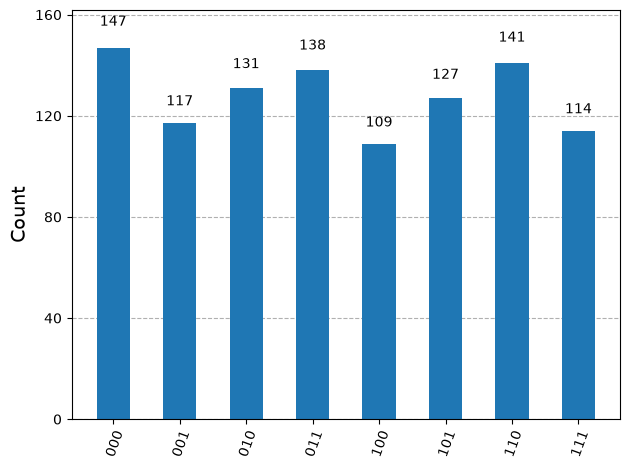

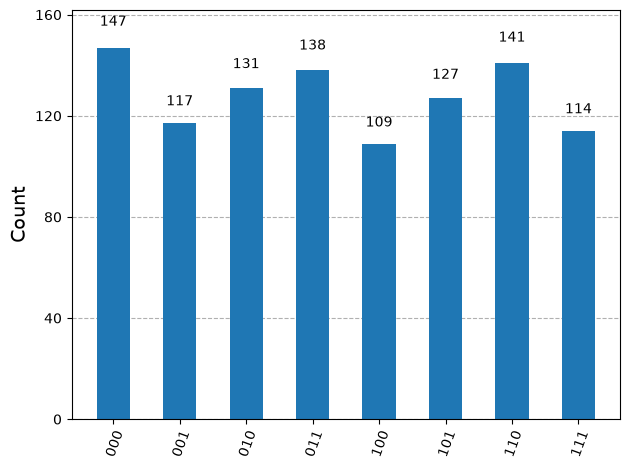

In [33]:
final = run_3sat_mystery_grover(num_iterations=0)
plot_histogram(final)

### Code: one iteration

**What this cell does.** It runs a single Grover iteration. The solution `011` should already stand out at about **78%**, which is $\sin^2(3\theta)$ with $\sin\theta = 1/\sqrt8$. The same number appeared in the bar charts of section 5.

Running Grover's algorithm for 1 iterations
{'011': 823, '001': 30, '110': 37, '101': 24, '100': 28, '111': 32, '000': 27, '010': 23}
most frequent: '011' (Qiskit order c b a)  ->  a, b, c = (1, 1, 0)   P = 0.804


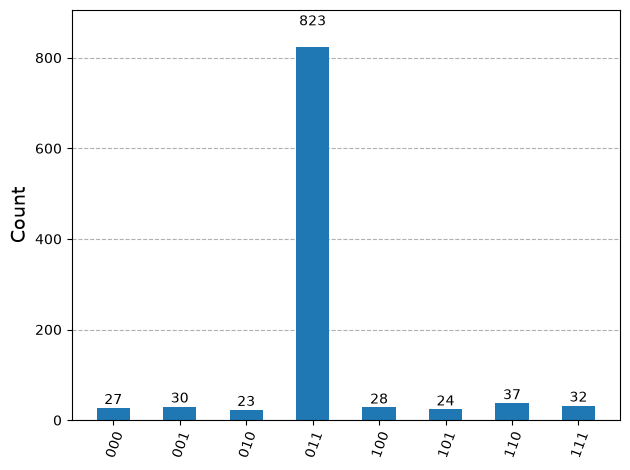

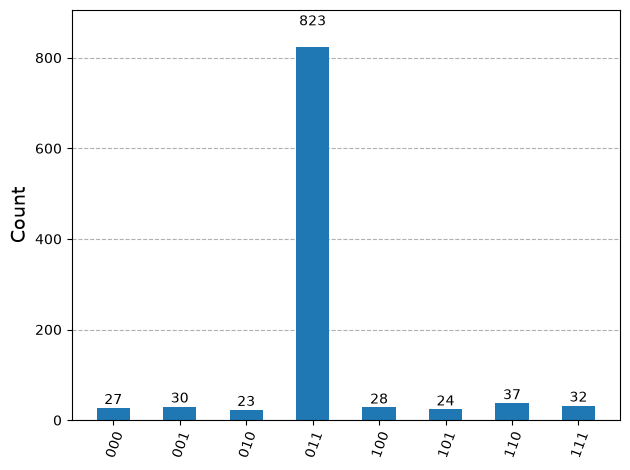

In [34]:
final = run_3sat_mystery_grover(num_iterations=1)
plot_histogram(final)

### Code: the optimal number of iterations (2)

**What this cell does.** It calls the driver without an iteration count, so it uses $k_{\text{opt}} = 2$. The solution should appear about **94.5%** of the time. That is the best achievable for $N=8$, $M=1$.

Running Grover's algorithm for 2 iterations
{'011': 971, '100': 10, '010': 7, '111': 8, '101': 9, '000': 5, '001': 9, '110': 5}
most frequent: '011' (Qiskit order c b a)  ->  a, b, c = (1, 1, 0)   P = 0.948


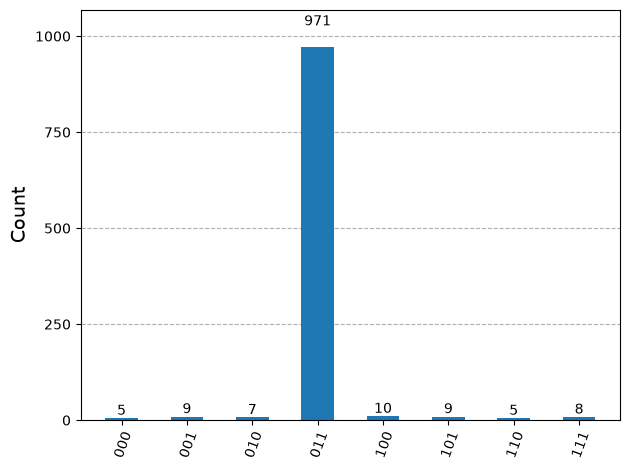

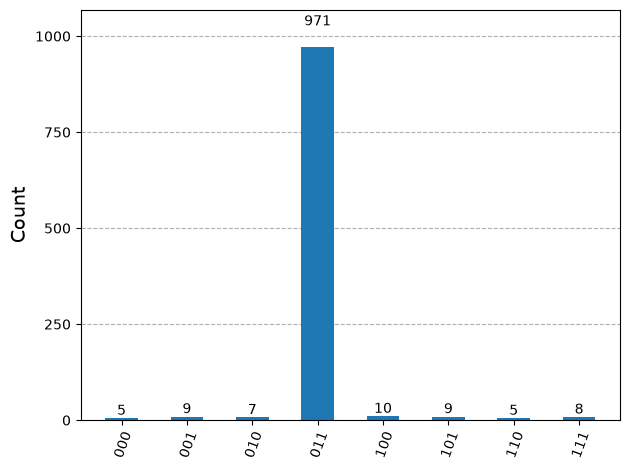

In [35]:
final = run_3sat_mystery_grover()
plot_histogram(final)

### Code: three iterations (over-rotation)

**What this cell does.** It runs one iteration **too many**. The state rotates past the solution and its probability **drops** to about 33%, i.e. $\sin^2(7\theta)$. This is the over-rotation effect from section 7, now seen with a real logic oracle. If we kept going, the probability would oscillate and rise again later.

Running Grover's algorithm for 3 iterations
{'100': 101, '011': 360, '010': 78, '001': 112, '110': 100, '000': 80, '111': 94, '101': 99}
most frequent: '011' (Qiskit order c b a)  ->  a, b, c = (1, 1, 0)   P = 0.352


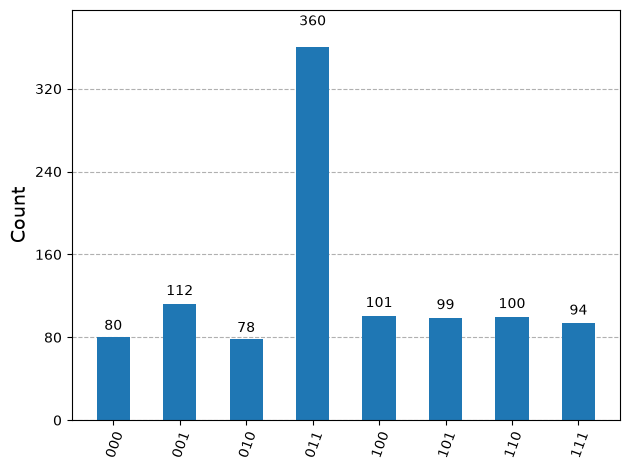

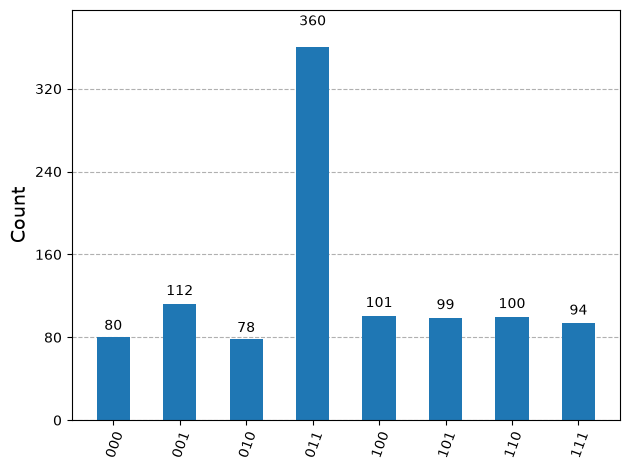

In [36]:
final = run_3sat_mystery_grover(num_iterations=3)
plot_histogram(final)

## 9. The library way: `PhaseOracle` + `Grover` on a 32-card 3-SAT

Building oracles by hand is instructive but tedious: our 3-variable formula needed 23 qubits. Qiskit can **synthesise** a phase oracle straight from a Boolean formula, and `qiskit_algorithms.Grover` runs the whole algorithm for us.

### The problem: which card is it?
Take a 32-card deck (7, 8, 9, 10, J, Q, K, A in ♠ ♥ ♦ ♣) and describe each card with 5 Boolean features:

| Variable | Meaning |
|---|---|
| $x_1$ | the card is a number (7, 8, 9, 10) |
| $x_2$ | the card is red (♥ ♦) |
| $x_3$ | the suit has a sharp edge on top (♠ ♦) |
| $x_4$ | the card is at an odd position (7, 9, J, K) |
| $x_5$ | the card is a middle value (9, 10, J, Q) |

$2^5 = 32$, so every card has a unique 5-bit code. We look for a card that satisfies all 9 clauses:

$F = \overbrace{( x_1 \lor x_2 \lor x_5)}^{c_1} \land \overbrace{( x_1 \lor x_2 \lor \neg x_5)}^{c_2} \land \overbrace{( x_1 \lor \neg x_2 \lor x_5)}^{c_3} \land \overbrace{( \neg x_1 \lor  x_2 \lor  x_5)}^{c_4} \land \overbrace{( \neg x_1 \lor  x_2 \lor \neg x_5)}^{c_5} \land$

$\overbrace{( \neg x_1 \lor \neg x_2 \lor x_4)}^{c_6} \land \overbrace{( \neg x_2 \lor x_3 \lor \neg x_4)}^{c_7} \land \overbrace{(\neg x_2 \lor \neg x_3 \lor x_4)}^{c_8}   \land  \overbrace{( \neg x_2 \lor \neg x_3 \lor \neg x_4)}^{c_9}$

|clause | expression | in words |
| - | - | - |
|$c_1$| $x_1\lor x_2\lor x_5$ |number or red or middle value|
|$c_2$| $x_1 \lor x_2 \lor \neg x_5$ |number or red or not middle value|
|$c_3$| $x_1 \lor \neg x_2 \lor x_5$ |number or black or middle value|
|$c_4$| $\neg x_1 \lor  x_2 \lor  x_5$ |letter or red or middle value|
|$c_5$| $\neg x_1 \lor  x_2 \lor \neg x_5$ |letter or red or not middle value|
|$c_6$| $\neg x_1 \lor \neg x_2 \lor x_4$ |letter or black or odd position|
|$c_7$| $\neg x_2 \lor x_3 \lor \neg  x_4$ |black or sharp edge or even position|
|$c_8$| $\neg x_2 \lor \neg x_3 \lor x_4$ |black or no sharp edge or odd position|
|$c_9$| $\neg x_2 \lor \neg x_3 \lor \neg  x_4$|black or no sharp edge or even position|

### Code: the formula in DIMACS-CNF format

**What this cell does.** It writes the formula in **DIMACS CNF**, the standard text format used by SAT solvers:
- lines starting with `c` are comments;
- `p cnf 5 9` declares 5 variables and 9 clauses;
- each following line is one clause: the number `k` means $x_k$, `-k` means $\neg x_k$, and `0` ends the clause. For example, `1 2 -5 0` is $(x_1 \lor x_2 \lor \neg x_5)$.

In [37]:
logical_exp_CNF = """
c coding our problem in 3-SAT format
p cnf 5 9
1 2 5 0
1 2 -5 0
1 -2 5 0
-1 2 5 0
-1 2 -5 0
-1 -2 4 0
-2 3 -4 0
-2 -3 4 0
-2 -3 -4 0
"""

### Code: synthesise the oracle with `PhaseOracle`

**What this cell does.**
- `oracle_from_dimacs(text)` saves the CNF text to a temporary file and calls `PhaseOracle.from_dimacs_file(...)`. This replaces Aqua's old `LogicalExpressionOracle`, which has been removed.
- `PhaseOracle` returns a **5-qubit** circuit that flips the sign of every assignment satisfying $F$. Compare that with the 23 qubits our hand-built oracle needed for just 3 variables: the library synthesises the formula efficiently, without one ancilla per clause.
- `oracle.evaluate_bitstring(b)` evaluates $F$ **classically** on a bitstring. We use it to list all solutions by brute force, as a cross-check, and later to tell `Grover` what counts as a "good" outcome.

Oracle qubits: 5
Classical brute force, satisfying bitstrings (Qiskit order x5 x4 x3 x2 x1): ['10010']


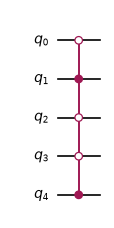

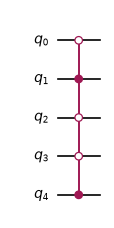

In [38]:
def oracle_from_dimacs(cnf_text):
    """PhaseOracle from DIMACS-CNF text (replaces Aqua's LogicalExpressionOracle)."""
    path = os.path.join(tempfile.gettempdir(), "grover_oracle.cnf")
    with open(path, "w") as fh:
        fh.write(cnf_text.strip() + "\n")
    return PhaseOracle.from_dimacs_file(path)

oracle = oracle_from_dimacs(logical_exp_CNF)
print("Oracle qubits:", oracle.num_qubits)

solutions = [b for b in (format(i, '05b') for i in range(32)) if oracle.evaluate_bitstring(b)]
print("Classical brute force, satisfying bitstrings (Qiskit order x5 x4 x3 x2 x1):", solutions)

oracle.draw(output='mpl', scale=0.6)

### Code: choose the number of iterations

**What this cell does.** It uses our formula to pick the iteration count. There is $M=1$ solution among $N=32$, so $k_{\text{opt}} = 4$, and the predicted success probability is $\sin^2(9\theta) \approx 99.9\%$.

The original notebook used 5 iterations. The prediction for 5 is $\sin^2(11\theta) \approx 86\%$: one too many, so it over-rotates.

In [39]:
n_vars, n_solutions = 5, len(solutions)
k_opt = optimal_iterations(n_vars, n_solutions)
theta = asin(sqrt(n_solutions / 2**n_vars))
for k in (k_opt, k_opt + 1):
    print(f"k = {k}:  predicted P(success) = {np.sin((2 * k + 1) * theta) ** 2:.4f}")

k = 4:  predicted P(success) = 0.9992
k = 5:  predicted P(success) = 0.8596


### Code: run Qiskit's `Grover`

**What this cell does.**
- `AmplificationProblem(oracle, is_good_state=...)` describes the search: which oracle to use and how to recognise a correct answer classically.
- `Grover(sampler=..., iterations=k_opt)` builds the circuit $H^{\otimes 5}$ followed by $(U_s U_f)^{k}$ and samples it. `StatevectorSampler` is an exact local simulator (it replaces Aqua's old `QuantumInstance`). `seed` makes the run reproducible.
- `grover.amplify(problem)` runs everything and returns a result object:
  - `result.top_measurement` is the most frequent bitstring;
  - `result.oracle_evaluation` is `True` if that bitstring really satisfies $F$;
  - `result.circuit_results[0]` holds the full counts.

> `Grover` can also be called with `iterations=[1, 2, 3, ...]`. It then tries increasing counts until it finds a good state, which is useful when you don't know $M$.

Top measurement      : 10010
Satisfies formula?   : True
P(top measurement)   : 0.9989


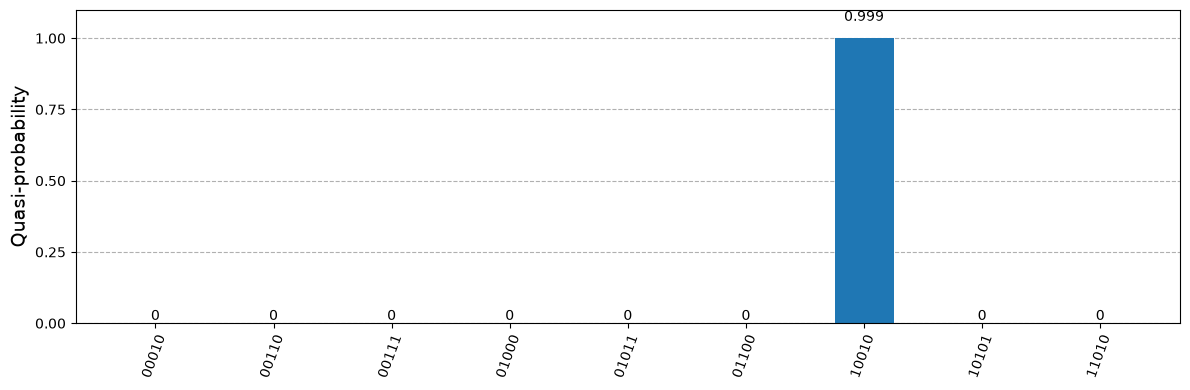

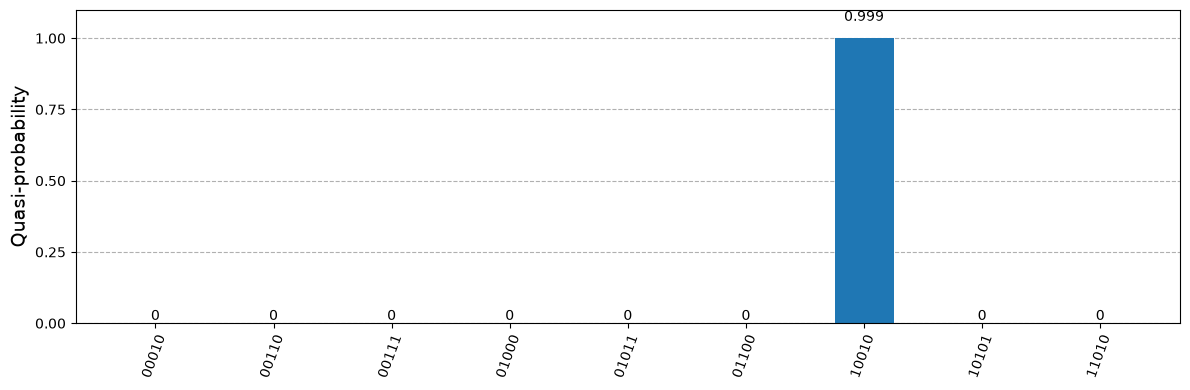

In [40]:
problem = AmplificationProblem(oracle, is_good_state=oracle.evaluate_bitstring)
grover = Grover(sampler=StatevectorSampler(default_shots=8192, seed=23), iterations=k_opt)
result = grover.amplify(problem)

print('Top measurement      :', result.top_measurement)
print('Satisfies formula?   :', result.oracle_evaluation)
counts = result.circuit_results[0]
print(f'P(top measurement)   : {counts[result.top_measurement] / sum(counts.values()):.4f}')
plot_histogram(counts, figsize=(12, 4))

### Code: decode the answer back into a card

**What this cell does.** It translates the bitstring into a playing card.
1. **Reverse the bitstring.** Variable $x_1$ is on qubit 0, which Qiskit prints last. Reversing gives $x_1 x_2 x_3 x_4 x_5$. The expected answer is `01001`: $\neg x_1, x_2, \neg x_3, \neg x_4, x_5$.
2. Build the 32-card deck and compute each card's 5 features using the definitions in the table above.
3. Print the card(s) whose features match the answer.

Reading the answer in words: a **letter** card ($\neg x_1$: J, Q, K, A) that is **red** ($x_2$), has **no sharp edge** ($\neg x_3$: ♥ or ♣, so with red this means ♥), is at an **even** position ($\neg x_4$: Q or A), and is a **middle** value ($x_5$: Q). That is the Queen of Hearts again.

In [41]:
answer = result.top_measurement[::-1]          # now in order x1 x2 x3 x4 x5
print("x1 x2 x3 x4 x5 =", " ".join(answer))

values = ['7', '8', '9', '10', 'J', 'Q', 'K', 'A']
suits = {'Spades': '♠', 'Hearts': '♥', 'Diamonds': '♦', 'Clubs': '♣'}

def features(value, suit):
    x1 = value in ('7', '8', '9', '10')
    x2 = suit in ('Hearts', 'Diamonds')
    x3 = suit in ('Spades', 'Diamonds')
    x4 = value in ('7', '9', 'J', 'K')
    x5 = value in ('9', '10', 'J', 'Q')
    return ''.join(str(int(b)) for b in (x1, x2, x3, x4, x5))

matches = [f"{v}{suits[s]} ({v} of {s})" for v in values for s in suits if features(v, s) == answer]
print("The card is:", matches)

x1 x2 x3 x4 x5 = 0 1 0 0 1
The card is: ['Q♥ (Q of Hearts)']


## 10. Beyond search: Grover Adaptive Search for optimisation

Grover finds an $x$ with $f(x)=1$. Can it also find the **minimum** of a function? Yes, by searching repeatedly with a moving threshold. This is **Grover Adaptive Search (GAS)** [Gilliam, Woerner, Gonciulea, arXiv:1912.04088](https://arxiv.org/abs/1912.04088).

### How GAS works
We want to minimise $f(x)$ over binary vectors $x \in \{0,1\}^n$.
1. Start with a threshold $y$, the value of some random $x$.
2. Build an oracle that marks every $x$ with $f(x) < y$, i.e. every "better than the best so far".
   - The value $f(x) - y$ is computed **into a register of `num_value_qubits` qubits** in two's-complement form (the `Q(x)` block in the circuit). The oracle then simply checks the **sign qubit**: a negative value means "better".
3. Run Grover with a (randomly chosen) number of iterations and measure. If the measured $x$ really is better, it becomes the new threshold $y$.
4. Repeat. Each improvement **shrinks** the set of marked states. Stop after `num_iterations` consecutive attempts that bring no improvement.

GAS is **randomised**: different runs may take different paths, but they should reach the same optimum. We check each answer against an exact classical solver.

### QUBO problems
GAS is a natural fit for **QUBO** (Quadratic Unconstrained Binary Optimisation) problems: minimise $x^T Q x + c^T x$ with $x_i \in \{0,1\}$. Many combinatorial problems (Max-Cut, scheduling, portfolio selection, …) can be written this way.

### Code: helpers to build and check a problem

**What this cell does.** It defines two small helpers so each example stays short.

**`solve_with_gas(qp, num_value_qubits, num_iterations, seed)`**
- creates a `GroverOptimizer`:
  - `num_value_qubits` is the number of qubits that hold $f(x)$ in two's complement. With $k$ qubits the representable range is $[-2^{k-1}, 2^{k-1}-1]$, so 6 qubits cover $-32 \dots 31$. **If the objective can fall outside this range, the result is wrong**, so pick it generously.
  - `num_iterations` means "stop after this many rounds without improvement". It is *not* the number of Grover iterations per round.
  - `sampler=StatevectorSampler(seed=...)` is an exact local simulator with a fixed seed, for reproducibility.
- calls `.solve(qp)` and returns the result. `result.x` is the best assignment and `result.fval` the objective value there.

**`validate_results(problem, results)`**, adapted from notebook 504, solves the same problem **exactly** with `MinimumEigenOptimizer(NumPyMinimumEigensolver())`, a classical brute-force solver. It prints both answers side by side and whether they agree.

In [42]:
def solve_with_gas(qp, num_value_qubits=6, num_iterations=10, seed=921):
    grover_optimizer = GroverOptimizer(num_value_qubits, num_iterations=num_iterations,
                                       sampler=StatevectorSampler(seed=seed))
    return grover_optimizer.solve(qp)

def validate_results(problem, results):
    """Compare a GroverOptimizer result with the exact classical optimum."""
    exact = MinimumEigenOptimizer(NumPyMinimumEigensolver()).solve(problem)
    print(f"GAS   : x = {results.x},  f(x) = {results.fval}")
    print(f"Exact : x = {exact.x},  f(x) = {exact.fval}")
    agree = bool(np.allclose(exact.x, results.x) and np.isclose(exact.fval, results.fval))
    print("Agree :", agree)

### 10.1 Example from the GAS paper

$$\min_{x\in\{0,1\}^3}\; -x_0 + 2x_1 - 3x_2 - 2x_0x_2 - x_1x_2$$

### Code: build the problem with docplex

**What this cell does.** It writes the optimisation problem in a readable, mathematical style with **docplex** (IBM's modelling library) and converts it to a Qiskit `QuadraticProgram`:
- `Model()` creates an empty model;
- `binary_var(name=...)` declares a variable that can only be 0 or 1;
- `minimize(...)` sets the objective;
- `from_docplex_mp(model)` converts it into the `QuadraticProgram` that `GroverOptimizer` understands;
- `prettyprint()` shows the problem in readable form, so you can confirm it was entered correctly.

In [43]:
model = Model()
x0 = model.binary_var(name='x0')
x1 = model.binary_var(name='x1')
x2 = model.binary_var(name='x2')
model.minimize(-x0 + 2*x1 - 3*x2 - 2*x0*x2 - 1*x1*x2)
qp = from_docplex_mp(model)
print(qp.prettyprint())

Problem name: docplex_model1

Minimize
  -2*x0*x2 - x1*x2 - x0 + 2*x1 - 3*x2

Subject to
  No constraints

  Binary variables (3)
    x0 x1 x2



### Code: solve with GAS and validate

**What this cell does.** It runs Grover Adaptive Search with 6 value qubits, so the circuit uses 3 + 6 = 9 qubits. It prints the full result with `prettyprint()` and then checks it against the exact solver.

**Expected:** $x = (1, 0, 1)$ with $f = -1 - 3 - 2 = -6$.

In [44]:
results = solve_with_gas(qp)
print(results.prettyprint())
print()
validate_results(qp, results)

objective function value: -6.0
variable values: x0=1.0, x1=0.0, x2=1.0
status: SUCCESS

GAS   : x = [1. 0. 1.],  f(x) = -6.0
Exact : x = [1. 0. 1.],  f(x) = -6.0
Agree : True


### 10.2 A linear problem (no quadratic terms): vaccine priority

Suppose we must decide which groups to vaccinate first:
- $x_0$: health professionals and emergency services (weight −4)
- $x_1$: students (weight −2)
- $x_2$: other citizens (weight +11)

$$\min_{x\in\{0,1\}^3}\; -4x_0 - 2x_1 + 11x_2$$

With no quadratic terms, each variable can be decided on its own: set $x_i = 1$ exactly when its weight is negative. So the answer is $x = (1, 1, 0)$ with $f = -6$. An easy problem like this is a good sanity check for the algorithm.

### Code: build, solve and validate the linear problem

**What this cell does.** It builds, solves and checks the problem in one cell, following the same three steps as 10.1: build the model with docplex, solve with GAS, compare with the exact solver.

In [45]:
model = Model()
x0 = model.binary_var(name='x0')
x1 = model.binary_var(name='x1')
x2 = model.binary_var(name='x2')
model.minimize(-4*x0 - 2*x1 + 11*x2)
qp = from_docplex_mp(model)
print(qp.prettyprint())

results = solve_with_gas(qp)
validate_results(qp, results)

Problem name: docplex_model2

Minimize
  -4*x0 - 2*x1 + 11*x2

Subject to
  No constraints

  Binary variables (3)
    x0 x1 x2

GAS   : x = [1. 1. 0.],  f(x) = -6.0
Exact : x = [1. 1. 0.],  f(x) = -6.0
Agree : True


### 10.3 A fully quadratic problem

$$\min_{x\in\{0,1\}^3}\; 4x_0^2 - 3x_0x_1 + 2x_1^2 - 5x_1x_2 + x_2^2 + 3x_2x_0 - 5x_0 + 3x_1 - 2x_2$$

Every pair of variables interacts, so the variables can no longer be decided one at a time.

### Code: build, solve and validate the quadratic problem

**What this cell does.** It runs the same build → solve → validate steps.

**Note:** for binary variables $x_i^2 = x_i$, so the squared terms are really linear terms in disguise. The printout may show them as quadratic, but the optimiser handles them correctly.

**Expected:** $x = (1, 1, 1)$ with $f = -2$.

In [46]:
model = Model()
x0 = model.binary_var(name='x0')
x1 = model.binary_var(name='x1')
x2 = model.binary_var(name='x2')
model.minimize(4*x0**2 - 3*x0*x1 + 2*x1**2 - 5*x1*x2 + x2**2 + 3*x2*x0 - 5*x0 + 3*x1 - 2*x2)
qp = from_docplex_mp(model)
print(qp.prettyprint())

results = solve_with_gas(qp)
validate_results(qp, results)

Problem name: docplex_model3

Minimize
  4*x0^2 - 3*x0*x1 + 3*x0*x2 + 2*x1^2 - 5*x1*x2 + x2^2 - 5*x0 + 3*x1 - 2*x2

Subject to
  No constraints

  Binary variables (3)
    x0 x1 x2

GAS   : x = [1. 1. 1.],  f(x) = -2.0
Exact : x = [1. 1. 1.],  f(x) = -2.0
Agree : True


### 10.4 Maximisation

GAS is internally a minimiser. A **maximisation** problem is handled by minimising $-f(x)$. `GroverOptimizer` does this automatically and reports `fval` back in the original (maximised) sense.

### Code: maximise $-x_0 + 2x_1$

**What this cell does.** It builds a 2-variable problem with `model.maximize(...)`, solves it with 4 value qubits, and validates the result.

**Expected:** set $x_0=0$ (its weight is negative) and $x_1=1$, giving $f = 2$.

In [47]:
model = Model()
x_0 = model.binary_var(name='x0')
x_1 = model.binary_var(name='x1')
model.maximize(-x_0 + 2*x_1)
qp = from_docplex_mp(model)

results = solve_with_gas(qp, num_value_qubits=4, num_iterations=8)
validate_results(qp, results)

GAS   : x = [0. 1.],  f(x) = 2.0
Exact : x = [0. 1.],  f(x) = 2.0
Agree : True


### 10.5 Edge case: an all-zero objective

What if no assignment can ever beat the starting threshold? Here $f(x) = 0$ for every $x$, so the oracle never marks anything. Grover then cannot amplify anything: measurements are uniform and never improve on the threshold. After `num_iterations` failed rounds GAS stops and returns $f = 0$.

This checks that the algorithm terminates gracefully when no "better" solution exists.

### Code: zero objective

**What this cell does.** It builds $\min\, 0\cdot x_0 + 0\cdot x_1$ and solves it with just **1** value qubit (enough to represent 0) and `num_iterations=1`. It should immediately return `fval = 0.0`. Any `x` is optimal, since all values are equal.

In [48]:
model = Model()
x_0 = model.binary_var(name='x0')
x_1 = model.binary_var(name='x1')
model.minimize(0*x_0 + 0*x_1)
qp = from_docplex_mp(model)

results = solve_with_gas(qp, num_value_qubits=1, num_iterations=1)
print("x =", results.x, "  fval =", results.fval)

x = [0. 0.]   fval = 0.0


## 11. Running on (noisy) hardware

On real devices every gate has a small error, and multi-controlled gates must be decomposed into many 2-qubit gates. **Deeper circuits accumulate more noise**, so the amplified peak shrinks. Hardware also only offers a few native gates (for IBM: `ecr`, `sx`, `x`, `rz`) and limited connectivity between qubits. The **transpiler** rewrites each circuit to fit.

We first study this **offline**, with a *fake backend*: a snapshot of a real IBM device's layout and error rates. Then, optionally, we run on real hardware.

### Code: how big do our circuits get on real hardware?

**What this cell does.** It transpiles four of our circuits for `FakeBrisbane`, a model of a 127-qubit IBM Eagle device, and prints:
- **depth**: the number of sequential gate layers (roughly, runtime);
- **2-qubit gates**: the number of `ecr` gates, the main source of error.

`generate_preset_pass_manager(optimization_level=3, backend=...)` is Qiskit's standard transpiler pipeline at its most aggressive optimisation setting.

**What to expect:** the 2-qubit circuit needs only a handful of 2-qubit gates. The 5-qubit, 4-iteration circuit needs well over a hundred. The hand-built 23-qubit 3-SAT circuit needs over a thousand, which is far beyond what today's devices can execute reliably.

In [49]:
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeBrisbane

fake = FakeBrisbane()
pm = generate_preset_pass_manager(optimization_level=3, backend=fake, seed_transpiler=1)

_, _, sat_qc = grovers_algorithm(_3sat_mystery_3, 3, 23)
test_circuits = {
    "2 qubits, 1 of 4, k=1": grover2,
    "3 qubits, 2 of 8, k=1": groverCircuit,
    "5 qubits, 1 of 32, k=4": qc5,
    "3-SAT by hand (23 qubits), k=2": sat_qc,
}
isa_circuits = {}
print(f"{'circuit':34s} {'depth':>7s} {'2-qubit gates':>14s}")
for name, qc in test_circuits.items():
    isa = pm.run(qc)
    isa_circuits[name] = isa
    print(f"{name:34s} {isa.depth():7d} {isa.count_ops().get('ecr', 0):14d}")

Running Grover's algorithm for 2 iterations
circuit                              depth  2-qubit gates
2 qubits, 1 of 4, k=1                   20              2
3 qubits, 2 of 8, k=1                   86             16
5 qubits, 1 of 32, k=4                1985            517
3-SAT by hand (23 qubits), k=2        2316           1232


### Code: noisy simulation with the fake device's error model

**What this cell does.** It builds `AerSimulator.from_backend(fake)`, a simulator that applies the fake device's measured gate and readout errors. It then runs the three small circuits on it and prints the probability of measuring a correct answer. (The 23-qubit circuit is skipped: it is too slow to simulate with noise and far too deep to give a meaningful answer.)

Each correct answer is checked with a small helper `is_correct(...)`:
- for `grover2` it is the `secret` from section 4;
- for `groverCircuit` it is `000` or `111`;
- for `qc5` it is `10110`.

**What to expect:** the 2-qubit circuit still works well, at around 90% or more. The 5-qubit circuit drops sharply, often close to random guessing (1/32 ≈ 3%). This is why near-term Grover experiments stay very small, and why error correction matters.

In [50]:
from qiskit_aer import AerSimulator

noisy_sim = AerSimulator.from_backend(fake)
correct = {
    "2 qubits, 1 of 4, k=1": {secret},
    "3 qubits, 2 of 8, k=1": {'000', '111'},
    "5 qubits, 1 of 32, k=4": {'10110'},
}

def is_correct(name, bitstring):
    return bitstring.replace(' ', '') in correct[name]

for name in correct:
    counts = noisy_sim.run(isa_circuits[name], shots=2048, seed_simulator=29).result().get_counts()
    p = sum(c for b, c in counts.items() if is_correct(name, b)) / 2048
    print(f"{name:26s}  P(correct) with noise = {p:.3f}")

2 qubits, 1 of 4, k=1       P(correct) with noise = 0.951
3 qubits, 2 of 8, k=1       P(correct) with noise = 0.862
5 qubits, 1 of 32, k=4      P(correct) with noise = 0.074


### Code: (optional) run on a real IBM Quantum device

**What this cell does.** If `RUN_ON_HARDWARE` is `True`, it:
1. connects to IBM Quantum using the token from the `IBM_QUANTUM_TOKEN` environment variable (set in section 3), and picks the **least busy** real device with at least 5 qubits;
2. transpiles the three small circuits for that device;
3. submits them in **one** job via `SamplerV2` (the current IBM Runtime primitive). The old `IBMQ` / `execute` / `job_monitor` workflow and devices such as `ibmq_16_melbourne` have been retired.
4. waits for the results, which can take minutes to hours depending on the queue, and prints `P(correct)` for each circuit.

It is **off by default**, so the notebook runs end to end without an account. To use it: get a token from [quantum.cloud.ibm.com](https://quantum.cloud.ibm.com), set `IBM_QUANTUM_TOKEN` in your environment, restart the kernel, and change the flag to `True`.

`pub.join_data().get_counts()` merges all classical registers of a result into one counts dictionary.

In [51]:
RUN_ON_HARDWARE = False

if RUN_ON_HARDWARE:
    from qiskit_ibm_runtime import SamplerV2

    hw_backend = get_backend("least_busy", token=_token_arg, min_num_qubits=5)
    hw_pm = generate_preset_pass_manager(optimization_level=3, backend=hw_backend)
    names = list(correct)
    hw_circuits = [hw_pm.run(test_circuits[name]) for name in names]

    job = SamplerV2(mode=hw_backend).run(hw_circuits, shots=1024)
    print("Submitted job", job.job_id(), "to", hw_backend.name, "- waiting for results ...")
    for name, pub in zip(names, job.result()):
        counts = pub.join_data().get_counts()
        p = sum(c for b, c in counts.items() if is_correct(name, b)) / 1024
        print(f"{name:26s}  P(correct) on {hw_backend.name} = {p:.3f}")
        display(plot_histogram(counts, title=name))
else:
    print("Skipping real hardware (set RUN_ON_HARDWARE = True to enable).")

Skipping real hardware (set RUN_ON_HARDWARE = True to enable).


## 12. Summary, exercises and references

### Key takeaways
1. **Structure.** Grover = uniform superposition, then $k$ repetitions of (oracle, diffuser), then measurement.
2. **Oracle.** It marks solutions with a $-1$ phase. A bit-flip oracle plus an output qubit in $|-\rangle$ gives the same effect through phase kickback. Oracles must **uncompute** their ancillas.
3. **Diffuser.** It performs inversion about the mean, $2|s\rangle\langle s| - I$, built as $H^{\otimes n} X^{\otimes n}\,\text{MCZ}\,X^{\otimes n} H^{\otimes n}$.
4. **Geometry.** Each iteration rotates the state by $2\theta$ with $\sin\theta = \sqrt{M/N}$, so $P(k) = \sin^2((2k+1)\theta)$.
5. **Iterations.** $k_{\text{opt}} = \lfloor \pi/(4\theta)\rfloor \approx \frac{\pi}{4}\sqrt{N/M}$. **Too many iterations hurt.**
6. **Speed-up.** $O(\sqrt N)$ oracle queries vs $O(N)$ classically. This is quadratic, not exponential, but it is provably optimal for unstructured search.
7. **Applications.** Satisfiability (3-SAT), and optimisation via Grover Adaptive Search, where repeated Grover searches with a falling threshold converge to the minimum.
8. **Hardware.** Circuit depth grows quickly with $n$ and $k$. On today's noisy devices only very small instances succeed.

### Exercises
1. In section 4, change the oracle so that it marks **two** positions out of four. What happens after one iteration? Explain it using $\theta$. (Hint: $\sin\theta = \sqrt{2/4}$.)
2. Use `phase_oracle` and `grover_circuit` from section 7 to search $n=6$ qubits for one marked state. Predict $k_{\text{opt}}$ and the success probability before you run it.
3. In the sweep of section 7, find the $k$ where the success probability is close to **zero** for $M=1$. Why does that happen?
4. Write a DIMACS formula of your own with exactly **two** solutions, and solve it with `PhaseOracle` + `Grover`. How many iterations should you use?
5. Remove the final `H` layer from `mover` in section 8 and re-run the 3-SAT search. Compare the histograms and explain the difference.
6. Formulate a 4-variable QUBO of your own (for example a tiny Max-Cut), solve it with `solve_with_gas`, and validate it. What is the smallest `num_value_qubits` that still gives the correct answer?

### References
1. L. K. Grover, *A fast quantum mechanical algorithm for database search*, STOC 1996, [arXiv:quant-ph/9605043](https://arxiv.org/abs/quant-ph/9605043).
2. M. Boyer, G. Brassard, P. Høyer, A. Tapp, *Tight bounds on quantum searching*, [arXiv:quant-ph/9605034](https://arxiv.org/abs/quant-ph/9605034) (multiple solutions, unknown $M$).
3. A. Gilliam, S. Woerner, C. Gonciulea, *Grover Adaptive Search for Constrained Polynomial Binary Optimization*, [arXiv:1912.04088](https://arxiv.org/abs/1912.04088).
4. M. A. Nielsen, I. L. Chuang, *Quantum Computation and Quantum Information*, Chapter 6.
5. Original 2-qubit card demo and 32-card 3-SAT example: Jean-Michel Torres, IBM Q Hub France, [github.com/jmit34/20191217](https://github.com/jmit34/20191217).